# Lecture 11 notebook: Three trend systems, end to end

Companion to Lecture 11 of *Systematic Trading Notes*. Every number and chart of the lecture comes from this notebook,
in the order of the lecture: the data (§2), from contracts to returns (§3), what the data contain (§4), the three systems
and the Kalman variant (§5–§7), comparing them across speeds (§8), evaluation (§9), two filters (§10), the portfolio
(§11) and out of sample (§12).

Data: twelve futures datasets from Kaggle (individual contract months, 1999–2022) and two Vanguard Treasury funds
and the S&P 500 from Yahoo Finance; FRED for the Treasury bill rate and the episode series of §4. The data stay
local: nothing downloaded here is published. Some cells take several minutes (the breakout loops, the speed sweep,
the probability of backtest overfitting); results are cached in `data/interim`.

In [1]:
import glob, json, os, shutil, sys, time, itertools, logging, calendar
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import yfinance as yf
from IPython.display import display
from plotly.subplots import make_subplots

from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "data" / "raw"
KAG = DATA / "kaggle"
CACHE = ROOT / "data" / "interim"; CACHE.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "lectures" / "11-three-trend-systems-end-to-end" / "figures"
pd.set_option("display.width", 250)

## 2. Getting the data (§2.3, §2.4)

The twelve Kaggle datasets are downloaded once with `kagglehub` (the token is read from `~/.kaggle/access_token` or
the environment variable `KAGGLE_API_TOKEN`); the funds come from Yahoo Finance and the bill rate from FRED.
Downloaded files are third-party data: they stay in their own folder and are read only as data.

In [2]:
DATASETS = ["cme-es", "cme-nasdaq", "cme-euro", "cme-jpy", "ice-us-dollar-index", "nymex-cl",
            "nymex-ng", "comex-gc", "cbot-corn", "cbot-soybeans", "cbot-wheat", "ice-cocoa"]
missing = [n for n in DATASETS if not (KAG / n).exists()]
if missing:
    import kagglehub
    for name in missing:
        cache = kagglehub.dataset_download(f"choweric/{name}")
        shutil.copytree(cache, KAG / name, dirs_exist_ok=True)
for f, url in (("fred_DTB3.csv", "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3"),):
    if not (DATA / f).exists():
        pd.read_csv(url).to_csv(DATA / f, index=False)
print({n: len(glob.glob(str(KAG / n / "*.csv"))) for n in DATASETS})

{'cme-es': 92, 'cme-nasdaq': 92, 'cme-euro': 138, 'cme-jpy': 92, 'ice-us-dollar-index': 92, 'nymex-cl': 276, 'nymex-ng': 276, 'comex-gc': 266, 'cbot-corn': 117, 'cbot-soybeans': 161, 'cbot-wheat': 115, 'ice-cocoa': 115}


## The roll machinery (§3.2)

Loading the contracts (the yen files quote contracts up to December 2021 in units 10,000 times larger), the roll
calendars (volume, open interest, fixed), and the daily point change of the contract held.

In [3]:
import glob, os, sys
import numpy as np, pandas as pd

K = str(KAG)
MON = "FGHJKMNQUVXZ"
CYCLE = {"cme-es": "HMUZ", "cme-nasdaq": "HMUZ", "cme-euro": "HMUZ", "cme-jpy": "HMUZ", "ice-us-dollar-index": "HMUZ",
         "nymex-cl": MON, "nymex-ng": MON, "comex-gc": "GJMQVZ", "cbot-corn": "HKNUZ", "cbot-soybeans": "FHKNX",
         "cbot-wheat": "HKNUZ", "ice-cocoa": "HKNUZ"}
NAME = {"cme-es": "E-mini S&P 500", "cme-nasdaq": "E-mini Nasdaq-100", "cme-euro": "Euro FX", "cme-jpy": "Japanese yen",
        "ice-us-dollar-index": "US dollar index", "nymex-cl": "WTI crude oil", "nymex-ng": "Natural gas", "comex-gc": "Gold",
        "cbot-corn": "Corn", "cbot-soybeans": "Soybeans", "cbot-wheat": "Wheat", "ice-cocoa": "Cocoa"}


RESCALED = []


def load(ds):
    out = {}
    for f in glob.glob(os.path.join(K, ds, "*.csv")):
        n = os.path.basename(f)[:-4]
        if n[-5] not in CYCLE[ds]:
            continue
        x = pd.read_csv(f, parse_dates=["Date"]).set_index("Date").sort_index()
        x = x[~x.index.duplicated()]
        out[n] = x
    order = sorted(out, key=lambda n: (int(n[-4:]), MON.index(n[-5])))
    C = {n: out[n] for n in order}
    # the yen files quote contracts up to December 2021 in units 10,000 times larger (8,808 instead of 0.8808)
    if ds == "cme-jpy":
        for n in order:
            if int(n[-4:]) <= 2021:
                C[n] = C[n].copy()
                C[n][["Open", "High", "Low", "Close"]] /= 10_000
    return C


def schedule(C, rule, k=5, start="2000-01-01", end="2022-12-31"):
    """Held contract each day. rule: 'volume', 'oi' (first day the next contract has more), or 'fixed' (k trading days
    before the current contract's last traded day). Volume and OI rolls are forced at the latest k=2 days before."""
    names = list(C)
    days = pd.DatetimeIndex(sorted(set().union(*[c.index for c in C.values()]))).to_series().loc[start:end].index
    held = pd.Series(index=days, dtype=object)
    i = 0
    # first contract: the earliest one still trading at the start
    while i < len(names) - 1 and C[names[i]][C[names[i]].Volume > 0].index.max() < days[0] + pd.Timedelta(days=10):
        i += 1
    rolls = []
    for t in days:
        cur = names[i]
        if i < len(names) - 1:
            nxt = names[i + 1]
            c, n = C[cur], C[nxt]
            last = c[c.Volume > 0].index.max()
            pos = c.index[(c.index <= last)]
            left = (pos > t).sum()                                  # trading days left in the current contract
            col = {"volume": "Volume", "oi": "Open Interest"}.get(rule)
            go = False
            if rule == "fixed":
                go = left <= k
            else:
                go = left <= 2 or (left <= 40 and t in n.index and t in c.index and n.at[t, col] > c.at[t, col] and n.at[t, "Volume"] > 0)
            if go and t in n.index and t in c.index:
                rolls.append(dict(date=t, old=cur, new=nxt, old_px=c.at[t, "Close"], new_px=n.at[t, "Close"], days_left=left))
                i += 1
        held.loc[t] = names[i]
    return held, pd.DataFrame(rolls)


def series(C, held):
    days = held.index
    prev = held.shift(1)
    px = lambda n, t: C[n].Close.get(t, np.nan)
    d = pd.Series([px(prev.iloc[j], days[j]) - px(prev.iloc[j], days[j - 1]) if j else np.nan for j in range(len(days))], days)
    base = pd.Series([px(prev.iloc[j], days[j - 1]) if j else np.nan for j in range(len(days))], days)
    raw = pd.Series([px(held.iloc[j], days[j]) for j in range(len(days))], days)
    return d, base, raw

## 3. From contracts to returns: roll rules, the adjustment techniques, signals in matching units (§3.2–§3.5)

The three roll rules per market, the annual return of holding and rolling under each, the forecasts of EWMAC and a
50-day breakout on the additive, ratio and raw series, and where the additive series falls below zero.

In [4]:
import sys
import numpy as np, pandas as pd

pd.set_option("display.width", 250)
OUT = {}


def build(C, held):
    d, base, raw = series(C, held)
    d = d.fillna(0)
    last = raw.dropna().iloc[-1]
    additive = last - d[::-1].cumsum()[::-1].shift(-1).fillna(0)
    r = (d / base).where(base > 0).fillna(0)
    ratio = last / (1 + r)[::-1].cumprod()[::-1].shift(-1).fillna(1)
    return dict(d=d, base=base, raw=raw, additive=additive, ratio=ratio, r=r)


def ewmac(p, f=16, s=64, vol_span=36):
    diff = p.ewm(span=f).mean() - p.ewm(span=s).mean()
    vol = p.diff().ewm(span=vol_span).std()
    return diff / vol


def donchian(p, n=50):
    hi, lo = p.rolling(n).max().shift(1), p.rolling(n).min().shift(1)
    pos = pd.Series(np.nan, p.index)
    pos[p > hi] = 1; pos[p < lo] = -1
    return pos.ffill().fillna(0)


rows_rule, rows_sig = [], []
for ds in CYCLE:
    C = load(ds)
    S = {}
    for rule in ("volume", "oi", "fixed"):
        if rule == "fixed":
            _, Ro = schedule(C, "oi")
            k = int(Ro.days_left.median())
            held, R = schedule(C, "fixed", k=k)
        else:
            held, R = schedule(C, rule)
        S[rule] = build(C, held)
        yrs = len(S[rule]["r"]) / 252
        S[rule]["pa"] = (1 + S[rule]["r"]).prod() ** (1 / yrs) - 1
    rows_rule.append(dict(market=NAME[ds], fixed_k=k, **{f"{x}_pa": round(100 * S[x]["pa"], 2) for x in S},
                          max_gap_pp=round(100 * (max(S[x]["pa"] for x in S) - min(S[x]["pa"] for x in S)), 2),
                          corr_daily_vol_oi=round(S["volume"]["r"].corr(S["oi"]["r"]), 3)))
    B = S["oi"]
    fa, fr, fw = ewmac(B["additive"]), ewmac(B["ratio"]), ewmac(B["raw"].ffill())
    # wrong units: percentage volatility applied to an additive price difference
    wrong = (B["additive"].ewm(span=16).mean() - B["additive"].ewm(span=64).mean()) / (B["additive"].pct_change().ewm(span=36).std() * B["raw"].ffill())
    da, dr, dw = donchian(B["additive"]), donchian(B["ratio"]), donchian(B["raw"].ffill())
    rows_sig.append(dict(market=NAME[ds], ewmac_add_vs_ratio=round(fa.corr(fr), 3), ewmac_add_vs_raw=round(fa.corr(fw), 3),
                         ewmac_add_vs_wrong_units=round(fa.corr(wrong), 3),
                         donch_same_add_ratio=round((da == dr).mean(), 3), donch_same_add_raw=round((da == dw).mean(), 3),
                         additive_neg_share=round((B["additive"] <= 0).mean(), 3)))
    OUT[ds] = B
print(pd.DataFrame(rows_rule).set_index("market").to_string())
print(pd.DataFrame(rows_sig).set_index("market").to_string())
for ds in ("cbot-soybeans", "nymex-cl"):
    a = OUT[ds]["additive"]
    print(NAME[ds], "additive <= 0 from", a[a <= 0].index.min(), "to", a[a <= 0].index.max(), "min", round(a.min(), 2),
          "raw first", OUT[ds]["raw"].dropna().iloc[0], "additive first", round(a.iloc[0], 2), "ratio first", round(OUT[ds]["ratio"].iloc[0], 2))
pd.to_pickle(OUT, CACHE / "l11_series.pkl")

                   fixed_k  volume_pa  oi_pa  fixed_pa  max_gap_pp  corr_daily_vol_oi
market                                                                               
E-mini S&P 500           3       4.23   4.25      4.29        0.06              1.000
E-mini Nasdaq-100        2       3.58   3.41      3.41        0.17              0.999
Euro FX                  2      -0.54  -0.53     -0.53        0.01              1.000
Japanese yen             2      -3.15  -3.12     -3.13        0.03              1.000
US dollar index          2      -0.24  -0.24     -0.24        0.00              1.000
WTI crude oil            7       0.15  -1.79     -1.06        1.94              0.991
Natural gas             10     -18.20 -22.77    -21.09        4.57              0.987
Gold                    23       5.93   6.01      5.99        0.07              1.000
Corn                    22      -3.24  -3.76     -5.32        2.07              0.996
Soybeans                22       7.09   7.17      6.63

### One roll, three series; the long history; roll yield (§3.1, §3.5, §3.6; charts J.1–J.3)

          date          old          new  old_px  new_px  days_left
242 2020-03-11  CME_CLJ2020  CME_CLK2020   32.98   33.39          7
243 2020-04-13  CME_CLK2020  CME_CLM2020   22.41   29.26          6
244 2020-04-24  CME_CLM2020  CME_CLN2020   16.94   21.22         17
                K      M         held
2020-04-08  25.09  30.17  CME_CLK2020
2020-04-09  22.76  28.82  CME_CLK2020
2020-04-13  22.41  29.26  CME_CLM2020
2020-04-14  20.11  27.40  CME_CLM2020
2020-04-15  19.87  26.04  CME_CLM2020
2020-04-16  19.87  25.53  CME_CLM2020
2020-04-17  18.27  25.03  CME_CLM2020
              raw  additive   ratio
2020-04-08  25.09     19.27  35.296
2020-04-09  22.76     16.94  32.018
2020-04-13  29.26     16.59  31.526
2020-04-14  27.40     14.73  29.522
2020-04-15  26.04     13.37  28.056
2020-04-16  25.53     12.86  27.507
2020-04-17  25.03     12.36  26.968


                   price  hold  roll
market                              
Natural gas          5.0 -22.8 -27.8
Wheat                4.8  -7.8 -12.6
Corn                 5.2  -3.8  -8.9
WTI crude oil        5.1  -1.8  -6.9
Cocoa                4.9   1.1  -3.7
Gold                 8.4   6.0  -2.4
Japanese yen        -1.3  -3.1  -1.8
E-mini Nasdaq-100    4.8   3.4  -1.4
Euro FX              0.1  -0.5  -0.7
US dollar index      0.2  -0.2  -0.4
E-mini S&P 500       4.3   4.3  -0.1
Soybeans             5.1   7.2   2.1


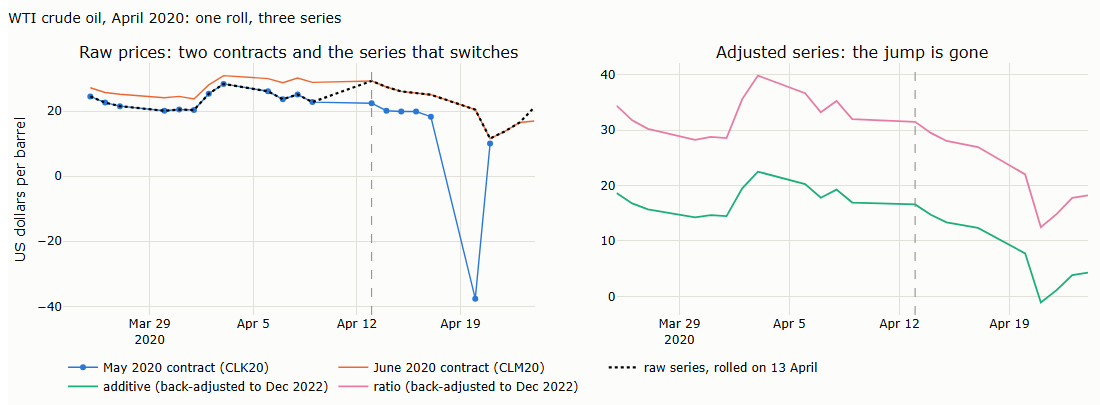

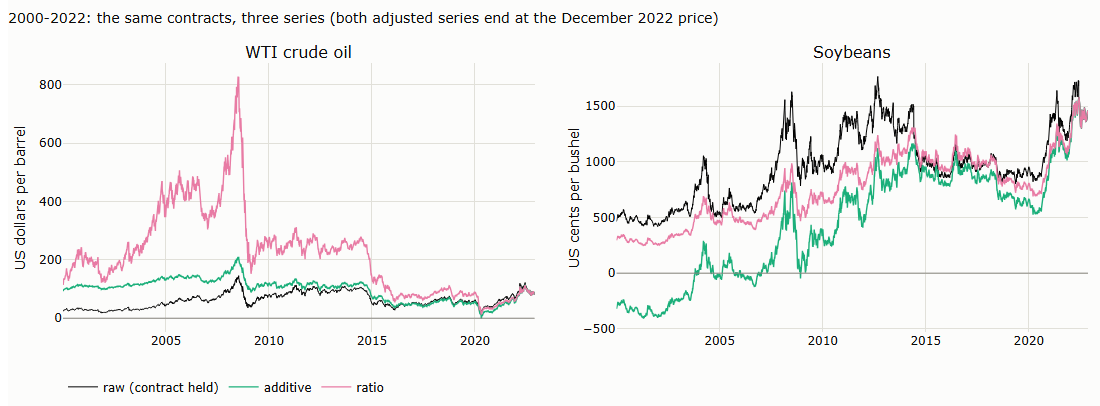

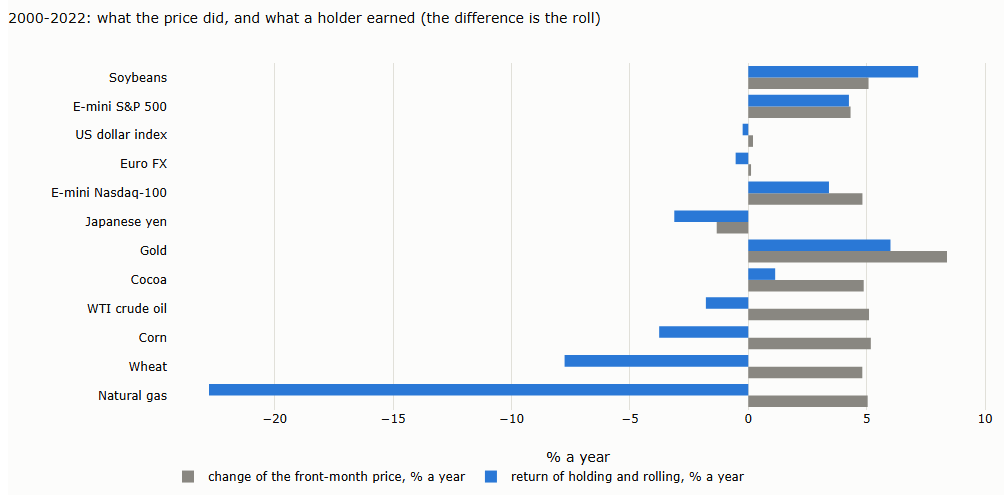

In [5]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

FIG.mkdir(parents=True, exist_ok=True)
S = pd.read_pickle(CACHE / "l11_series.pkl")          # open-interest roll rule

# ---- numbers for the one-roll example: crude oil, April 2020
C = load("nymex-cl")
held, R = schedule(C, "oi")
print(R[(R.date >= "2020-03-01") & (R.date <= "2020-05-31")].to_string())
k, m = C["CME_CLK2020"].Close, C["CME_CLM2020"].Close
w = slice("2020-03-25", "2020-04-24")
print(pd.concat({"K": k, "M": m, "held": held}, axis=1).loc["2020-04-08":"2020-04-17"].to_string())
B = S["nymex-cl"]
print(pd.concat({"raw": B["raw"], "additive": B["additive"], "ratio": B["ratio"]}, axis=1).loc["2020-04-08":"2020-04-17"].round(3).to_string())

# ---- J.1 one roll: two contracts, the stitched raw series, and the adjusted series
fig = make_subplots(rows=1, cols=2, subplot_titles=("Raw prices: two contracts and the series that switches", "Adjusted series: the jump is gone"),
                    horizontal_spacing=0.08)
fig.add_scatter(x=k.loc[w].index, y=k.loc[w], name="May 2020 contract (CLK20)", line=dict(color=SERIES[0], width=1.4), row=1, col=1)
fig.add_scatter(x=m.loc[w].index, y=m.loc[w], name="June 2020 contract (CLM20)", line=dict(color=SERIES[1], width=1.4), row=1, col=1)
fig.add_scatter(x=B["raw"].loc[w].index, y=B["raw"].loc[w], name="raw series, rolled on 13 April", line=dict(color="black", width=2.2, dash="dot"), row=1, col=1)
fig.add_scatter(x=B["additive"].loc[w].index, y=B["additive"].loc[w], name="additive (back-adjusted to Dec 2022)", line=dict(color=SERIES[2], width=1.8), row=1, col=2)
fig.add_scatter(x=B["ratio"].loc[w].index, y=B["ratio"].loc[w], name="ratio (back-adjusted to Dec 2022)", line=dict(color=SERIES[3], width=1.8), row=1, col=2)
roll_day = R[(R.date >= "2020-04-01") & (R.date <= "2020-04-30")].date.iloc[0]
for c_ in (1, 2):
    fig.add_vline(x=roll_day, line=dict(color=MUTED, width=1, dash="dash"), row=1, col=c_)
fig.update_yaxes(title_text="US dollars per barrel", row=1, col=1)
fig.update_layout(title="WTI crude oil, April 2020: one roll, three series", height=430, width=1100, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_01_one_roll", FIG)

# ---- J.2 long history: raw, additive, ratio for crude oil and soybeans
fig = make_subplots(rows=1, cols=2, subplot_titles=("WTI crude oil", "Soybeans"), horizontal_spacing=0.08)
for j, ds in enumerate(("nymex-cl", "cbot-soybeans")):
    B = S[ds]
    for nm, s, col, wd in (("raw (contract held)", B["raw"].ffill(), "black", 1.0), ("additive", B["additive"], SERIES[2], 1.4), ("ratio", B["ratio"], SERIES[3], 1.4)):
        fig.add_scatter(x=s.index, y=s, name=nm, line=dict(color=col, width=wd), showlegend=(j == 0), row=1, col=j + 1)
    fig.add_hline(y=0, line=dict(color=MUTED, width=1), row=1, col=j + 1)
fig.update_yaxes(title_text="US dollars per barrel", row=1, col=1)
fig.update_yaxes(title_text="US cents per bushel", row=1, col=2)
fig.update_layout(title="2000-2022: the same contracts, three series (both adjusted series end at the December 2022 price)",
                  height=430, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_02_three_series", FIG)

# ---- J.3 roll yield: price change against holding and rolling
rows = []
for ds, B in S.items():
    yrs = len(B["r"]) / 252
    hold = (1 + B["r"]).prod() ** (1 / yrs) - 1
    raw = B["raw"].dropna()
    price = (raw.iloc[-1] / raw.iloc[0]) ** (1 / ((raw.index[-1] - raw.index[0]).days / 365.25)) - 1
    rows.append(dict(market=NAME[ds], price=100 * price, hold=100 * hold, roll=100 * (hold - price)))
T = pd.DataFrame(rows).set_index("market").sort_values("roll")
print(T.round(1).to_string())
fig = go.Figure()
fig.add_bar(y=T.index, x=T.price, name="change of the front-month price, % a year", orientation="h", marker_color=MUTED)
fig.add_bar(y=T.index, x=T.hold, name="return of holding and rolling, % a year", orientation="h", marker_color=SERIES[0])
fig.update_layout(barmode="group", title="2000-2022: what the price did, and what a holder earned (the difference is the roll)",
                  xaxis_title="% a year", height=520, width=1000, margin=dict(t=80, l=160), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_03_roll_yield", FIG)
T.to_csv(CACHE / "l11_roll_yield.csv")

### The bond funds: price, total and excess returns (§3.7)

In [6]:
fd = yf.download(["VFITX", "VUSTX"], start="1999-12-31", end="2023-01-01", auto_adjust=False, progress=False)
tb = pd.to_numeric(pd.read_csv(DATA / "fred_DTB3.csv", index_col=0, parse_dates=True).iloc[:, 0], errors="coerce")
rows = {}
for t_ in ["VFITX", "VUSTX"]:
    c_, a_ = fd["Close"][t_].dropna(), fd["Adj Close"][t_].dropna()
    yrs = (c_.index[-1] - c_.index[0]).days / 365.25
    r_ = a_.pct_change().dropna(); b_ = (tb.reindex(r_.index).ffill() / 100 / 252).shift(1).fillna(0)
    rows[t_] = {"price % a year": 100 * ((c_.iloc[-1] / c_.iloc[0]) ** (1 / yrs) - 1), "total return % a year": 100 * ((a_.iloc[-1] / a_.iloc[0]) ** (1 / yrs) - 1),
                "excess return % a year": 100 * ((1 + r_ - b_).prod() ** (1 / yrs) - 1), "volatility %": 100 * r_.std() * np.sqrt(252)}
display(pd.DataFrame(rows).T.round(2))

,price % a year,total return % a year,excess return % a year,volatility %
VFITX,-0.08,4.06,2.49,4.80
VUSTX,-0.42,5.10,3.52,12.19


## 4. What the data contain (§4, chart J.4)

Episodes by simple rules: NBER recessions, bear markets of the S&P 500, VIX above 30, inflation above 4% and below 0,
zero rates, the Fed's QE and QT programmes and its rate increases.

                                       count  share_of_days                                                                                                                                                                                                                                                                                                          periods
episode                                                                                                                                                                                                                                                                                                                                                                     
Recession (NBER)                           3           0.09                                                                                                                                                                                                                   

WindowsPath('C:/Users/maxgn/New Trading Models/figures/11_three_trend_systems/11_04_episodes.html')

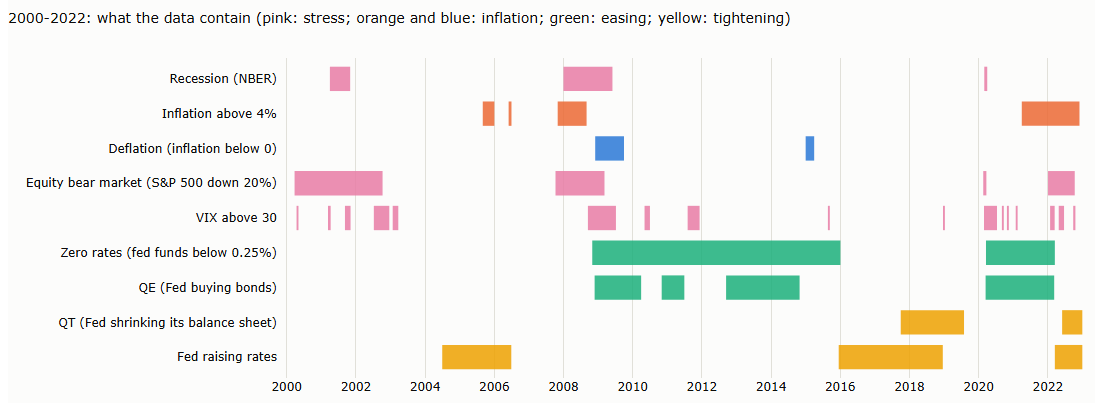

In [7]:
from pathlib import Path
import logging
import numpy as np, pandas as pd
import plotly.graph_objects as go
import yfinance as yf
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

RAW = DATA
A, B = "2000-01-01", "2022-12-31"


def fred(code):
    f = RAW / f"fred_{code}.csv"
    if not f.exists():
        pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}").to_csv(f, index=False)
    s = pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
    return pd.to_numeric(s, errors="coerce").dropna()


def merge(sp, gap_days):
    out = []
    for a, b in sp:
        if out and (a - out[-1][1]).days < gap_days:
            out[-1] = (out[-1][0], b)
        else:
            out.append((a, b))
    return out


def spells(mask, min_gap="0D"):
    m = mask.astype(bool)
    out, start, prev = [], None, None
    for t, v in m.items():
        if v and start is None:
            start = t
        if not v and start is not None:
            out.append((start, prev)); start = None
        prev = t
    if start is not None:
        out.append((start, prev))
    return out


rec = fred("USREC").loc[A:B]
cpi = fred("CPIAUCSL")
infl = (100 * cpi.pct_change(12)).loc[A:B]
vix = fred("VIXCLS").loc[A:B]
ff = fred("DFF").loc[A:B]
spx = yf.download("^GSPC", start="1999-01-01", end="2023-01-01", auto_adjust=True, progress=False)["Close"].squeeze()
spx.to_frame("close").to_csv(RAW / "l11_spx.csv")
dd = spx / spx.cummax() - 1

ep = {}
ep["Recession (NBER)"] = merge(spells(rec == 1), 95)
ep["Inflation above 4%"] = merge(spells(infl > 4), 95)
ep["Deflation (inflation below 0)"] = merge(spells(infl < 0), 95)
# bear markets: from the peak before a 20% fall to the trough
bears, in_bear, peak_t, trough_t = [], False, spx.index[0], None
pk = spx.cummax()
i = 0
s = spx.loc[A:B]
peak_val, peak_t = s.iloc[0], s.index[0]
low_val, low_t, bear = None, None, False
for t, v in spx.loc["1999":B].items():
    if not bear:
        if v > peak_val:
            peak_val, peak_t = v, t
        elif v <= 0.8 * peak_val:
            bear, low_val, low_t = True, v, t
    else:
        if v < low_val:
            low_val, low_t = v, t
        if v >= peak_val:                                   # recovered: the bear market ended at the trough
            bears.append((peak_t, low_t)); bear = False; peak_val, peak_t = v, t
if bear:
    bears.append((peak_t, low_t))
ep["Equity bear market (S&P 500 down 20%)"] = [(max(a, pd.Timestamp(A)), b) for a, b in bears if b >= pd.Timestamp(A)]
ep["VIX above 30"] = [(a, b) for a, b in merge(spells(vix > 30), 31) if (b - a).days >= 5]
ep["Zero rates (fed funds below 0.25%)"] = [(a, b) for a, b in merge(spells(ff < 0.25), 31) if (b - a).days >= 30]
# Fed programmes: official announcement and end dates
ep["QE (Fed buying bonds)"] = [(pd.Timestamp("2008-11-25"), pd.Timestamp("2010-03-31")), (pd.Timestamp("2010-11-03"), pd.Timestamp("2011-06-30")),
                               (pd.Timestamp("2012-09-13"), pd.Timestamp("2014-10-29")), (pd.Timestamp("2020-03-15"), pd.Timestamp("2022-03-09"))]
ep["QT (Fed shrinking its balance sheet)"] = [(pd.Timestamp("2017-10-01"), pd.Timestamp("2019-07-31")), (pd.Timestamp("2022-06-01"), pd.Timestamp(B))]
ep["Fed raising rates"] = [(pd.Timestamp("2004-06-30"), pd.Timestamp("2006-06-29")), (pd.Timestamp("2015-12-16"), pd.Timestamp("2018-12-19")),
                           (pd.Timestamp("2022-03-16"), pd.Timestamp(B))]

days = pd.bdate_range(A, B)
rows = []
for k, v in ep.items():
    cover = pd.Series(False, days)
    for a, b in v:
        cover.loc[a:b] = True
    rows.append(dict(episode=k, count=len(v), share_of_days=round(cover.mean(), 2),
                     periods="; ".join(f"{a:%b %Y}–{b:%b %Y}" if (a.year, a.month) != (b.year, b.month) else f"{a:%b %Y}" for a, b in v)))
T = pd.DataFrame(rows).set_index("episode")
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 200)
print(T.to_string())
print("VIX share of days > 30:", round((vix > 30).mean(), 3), " < 15:", round((vix < 15).mean(), 3), " median:", vix.median())
print("inflation max:", round(infl.max(), 1), infl.idxmax().date(), " min:", round(infl.min(), 1), infl.idxmin().date())
print("10y yield start/min/end:", fred("DGS10").loc[A:B].iloc[0], fred("DGS10").loc[A:B].min(), fred("DGS10").loc[A:B].idxmin().date(), fred("DGS10").loc[A:B].iloc[-1])
T.to_csv(CACHE / "l11_episodes.csv")

# ---- chart J.4: timeline
fig = go.Figure()
names = list(ep)[::-1]
colors = {"Recession (NBER)": SERIES[3], "Equity bear market (S&P 500 down 20%)": SERIES[3], "VIX above 30": SERIES[3],
          "Inflation above 4%": SERIES[1], "Deflation (inflation below 0)": SERIES[0], "Zero rates (fed funds below 0.25%)": SERIES[2],
          "QE (Fed buying bonds)": SERIES[2], "QT (Fed shrinking its balance sheet)": SERIES[4], "Fed raising rates": SERIES[4]}
for j, k in enumerate(names):
    for a, b in ep[k]:
        b2 = b if (b - a).days > 20 else a + pd.Timedelta(days=20)
        fig.add_shape(type="rect", x0=a, x1=b2, y0=j - 0.35, y1=j + 0.35, fillcolor=colors[k], line_width=0, opacity=0.85)
fig.add_scatter(x=[pd.Timestamp(A), pd.Timestamp(B)], y=[0, len(names) - 1], mode="markers", marker=dict(opacity=0), showlegend=False)
fig.update_yaxes(tickvals=list(range(len(names))), ticktext=names, range=[-0.6, len(names) - 0.4], showgrid=False)
fig.update_xaxes(range=[pd.Timestamp("1999-10-01"), pd.Timestamp("2023-03-01")], dtick="M24", tickformat="%Y")
fig.update_layout(title="2000-2022: what the data contain (pink: stress; orange and blue: inflation; green: easing; yellow: tightening)",
                  height=430, width=1100, margin=dict(t=70, l=270))
save_figure(fig, "11_04_episodes", FIG)

## §5.3 The volatility floor, checked; §5.4 the Kalman slope against EWMAC

Standalone checks on the series of §3; they run before the backtest systems are defined, which reuse some of the names.

In [8]:
"""Vol sizing: plain EWMA vs floor (half the 10-year median) vs blend (70% short + 30% 10-year mean).
EWMAC 16/64 per market on the additive series; returns in risk units (forecast x point change / vol)."""
import sys
import numpy as np, pandas as pd
S = pd.read_pickle(CACHE / "l11_series.pkl")
rows, pooled = [], {}
for ds, B in S.items():
    p, d = B["additive"], B["d"]
    sig = d.ewm(span=36, min_periods=30).std()
    long_med = sig.rolling(2520, min_periods=250).median()
    long_mean = sig.rolling(2520, min_periods=250).mean()
    vols = {"plain": sig, "floor": np.maximum(sig, 0.5 * long_med), "blend": 0.7 * sig + 0.3 * long_mean}
    raw_f = (p.ewm(span=16).mean() - p.ewm(span=64).mean()) / sig
    f = (raw_f / raw_f.abs().expanding(250).mean()).clip(-2, 2)          # average size 1, capped at 2
    out = {}
    for k, v in vols.items():
        pos = (f / v).shift(1)                                           # units per point of risk, decided yesterday
        r = (pos * d).loc["2001":]
        r = r / r.std()                                                   # same overall risk for all variants
        size = (1 / v).loc["2001":]; size = size / size.median()
        out[k] = r
        rows.append(dict(market=NAME[ds], variant=k, sharpe=round(np.sqrt(252) * r.mean(), 2), worst_day=round(r.min(), 1),
                         days_beyond_5=int((r.abs() > 5).sum()), max_size=round(size.max(), 1),
                         rolling_vol_max=round(r.rolling(63).std().max(), 2),
                         floor_binds=round(((0.5 * long_med) > sig).loc["2001":].mean(), 3) if k == "floor" else np.nan))
    pooled[ds] = out
T = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print(T.pivot(index="market", columns="variant", values=["sharpe", "worst_day", "max_size"]).to_string())
print(T[T.variant == "floor"].set_index("market")[["floor_binds"]].T.to_string())
port = {k: pd.concat({ds: pooled[ds][k] for ds in pooled}, axis=1).mean(axis=1) for k in ("plain", "floor", "blend")}
for k, r in port.items():
    r = r / r.std()
    print(f"portfolio {k:5s}: sharpe {np.sqrt(252) * r.mean():.2f}  worst day {r.min():.1f}  days beyond 4: {(r.abs() > 4).sum()}  "
          f"max 3-month vol / overall: {r.rolling(63).std().max():.2f}")
summ = T.groupby("variant")[["sharpe", "worst_day", "days_beyond_5", "max_size", "rolling_vol_max"]].median()
print(summ.to_string())

                  sharpe             worst_day             max_size            
variant            blend floor plain     blend floor plain    blend floor plain
market                                                                         
Cocoa              -0.66 -0.66 -0.66     -12.7 -15.3 -15.3      2.1   2.7   3.2
Corn                0.24  0.23  0.23      -7.3  -6.6  -6.6      3.4   4.0   4.0
E-mini Nasdaq-100   0.22  0.20  0.19     -10.4  -9.7  -9.5      1.9   2.8   3.3
E-mini S&P 500      0.11  0.14  0.14     -11.6 -12.1 -12.1      1.9   2.6   2.7
Euro FX             0.40  0.42  0.43      -7.9  -8.2  -8.1      1.8   2.2   2.6
Gold                0.06  0.08  0.08     -10.0  -8.9  -8.8      5.9   6.9   7.1
Japanese yen        0.19  0.20  0.20     -10.9 -10.9 -10.9      1.7   2.1   2.3
Natural gas         0.35  0.33  0.35      -7.0  -6.8  -6.7      2.6   2.8   3.8
Soybeans            0.35  0.34  0.34      -7.8  -7.5  -7.4      2.8   3.2   3.1
US dollar index     0.35  0.37  0.38    

In [9]:
"""Is the Kalman slope distinct from EWMAC? Level + slope model on the log of the ratio series (Lecture 4, §3).
K1: constant noise variances (steady state = Holt's smoothing, a linear filter).
K2: observation variance = current variance of daily log returns, process variances fixed at long-run levels,
    so the gain falls when volatility rises (more smoothing in turbulent markets).
Signal: slope divided by its standard deviation (the filter's own uncertainty).
For each Kalman speed, find the EWMAC speed with the highest forecast correlation; compare daily strategy returns."""
import sys
import numpy as np, pandas as pd
S = pd.read_pickle(CACHE / "l11_series.pkl")


def kalman(y, q_level, q_slope, r):
    n = len(y); x = np.array([y[0], 0.0]); P = np.eye(2) * 1.0
    F = np.array([[1.0, 1.0], [0.0, 1.0]]); Q = np.diag([q_level, q_slope])
    slope, sd = np.full(n, np.nan), np.full(n, np.nan)
    rr = np.broadcast_to(np.asarray(r, float), (n,))
    for t in range(n):
        x = F @ x; P = F @ P @ F.T + Q
        if np.isfinite(y[t]) and np.isfinite(rr[t]):
            s = P[0, 0] + rr[t]; k = P[:, 0] / s
            x = x + k * (y[t] - x[0]); P = P - np.outer(k, P[0, :])
        slope[t], sd[t] = x[1], np.sqrt(P[1, 1])
    return slope, sd


def ewmac(p, f):
    return (p.ewm(span=f).mean() - p.ewm(span=4 * f).mean()) / p.diff().ewm(span=36).std()


def strat(signal, d, sig):
    f = signal / signal.abs().expanding(250).mean()
    r = (f.clip(-2, 2) / sig).shift(1) * d
    r = r.loc["2002":]
    return r / r.std()


rows = []
EW = [4, 8, 16, 32, 64]
for ds, B in S.items():
    lp = np.log(B["ratio"]); y = lp.values
    lr = lp.diff()
    v_long = lr.var()
    sig = B["d"].ewm(span=36, min_periods=30).std()
    ew = {f: ewmac(B["additive"], f) for f in EW}
    ew_r = {f: strat(ew[f], B["d"], sig) for f in EW}
    for ratio in (1e-4, 1e-5, 1e-6):                       # q_slope / r: higher = faster
        for kind in ("K1 constant", "K2 vol-linked"):
            r_obs = v_long if kind.startswith("K1") else lr.ewm(span=36, min_periods=30).var().bfill().values
            sl, sd = kalman(y, q_level=0.0, q_slope=ratio * v_long, r=r_obs)
            ks = pd.Series(sl / sd, lp.index)
            corr = {f: ks.corr(ew[f]) for f in EW}
            best = max(corr, key=corr.get)
            kr = strat(ks, B["d"], sig)
            rows.append(dict(market=NAME[ds], speed=ratio, kind=kind, best_ewmac=f"{best}/{4 * best}", forecast_corr=corr[best],
                             return_corr=kr.corr(ew_r[best]), sharpe_k=np.sqrt(252) * kr.mean(), sharpe_e=np.sqrt(252) * ew_r[best].mean()))
T = pd.DataFrame(rows)
pd.set_option("display.width", 250)
G = T.groupby(["kind", "speed"]).agg(best_ewmac=("best_ewmac", lambda s: s.mode().iloc[0]), forecast_corr=("forecast_corr", "median"),
                                     forecast_corr_min=("forecast_corr", "min"), return_corr=("return_corr", "median"),
                                     sharpe_kalman=("sharpe_k", "median"), sharpe_ewmac=("sharpe_e", "median"))
print(G.round(3).to_string())
print(T[(T.speed == 1e-5)].pivot(index="market", columns="kind", values="return_corr").round(3).to_string())

                       best_ewmac  forecast_corr  forecast_corr_min  return_corr  sharpe_kalman  sharpe_ewmac
kind          speed                                                                                          
K1 constant   0.000001     32/128          0.901              0.819        0.926          0.206         0.225
              0.000010      16/64          0.912              0.819        0.944          0.169         0.202
              0.000100       8/32          0.910              0.815        0.948          0.066         0.110
K2 vol-linked 0.000001     32/128          0.925              0.902        0.932          0.199         0.225
              0.000010      16/64          0.933              0.901        0.950          0.181         0.202
              0.000100       8/32          0.934              0.897        0.952          0.050         0.110
kind               K1 constant  K2 vol-linked
market                                       
Cocoa                    0.9

## The backtest data: series from 1999, systems and the speed sweep (§5–§8)

The same contracts, rolled on the open-interest calendar from 1999, so that the slowest speeds have warmed up by
2001; the two bond funds as excess-return indices. Then the four systems (EWMAC, the breakout, the Kalman slope and
cross-sectional momentum) with the full design, and the sweep across their speeds (charts J.5 and J.6 use it).

In [10]:
import sys
import numpy as np, pandas as pd
OUT = {}
for ds in CYCLE:
    C = load(ds)
    held, R = schedule(C, "oi", start="1999-01-01")
    held = held.dropna()
    d, base, raw = series(C, held)
    d = d.fillna(0); last = raw.dropna().iloc[-1]
    additive = last - d[::-1].cumsum()[::-1].shift(-1).fillna(0)
    r = (d / base).where(base > 0).fillna(0)
    ratio = last / (1 + r)[::-1].cumprod()[::-1].shift(-1).fillna(1)
    OUT[ds] = dict(d=d, base=base, raw=raw, additive=additive, ratio=ratio, r=r)
    print(ds, raw.first_valid_index().date(), len(R), "rolls")
pd.to_pickle(OUT, CACHE / "l11_series99.pkl")

cme-es 1999-09-20 91 rolls


cme-nasdaq 1999-09-17 91 rolls


cme-euro 1999-03-09 91 rolls


cme-jpy 1999-03-09 91 rolls


ice-us-dollar-index 1999-03-18 91 rolls


...

comex-gc 1999-01-04 137 rolls


cbot-corn 1999-01-04 114 rolls


cbot-soybeans 1999-01-04 114 rolls


cbot-wheat 1999-01-27 114 rolls


ice-cocoa 1999-01-04 114 rolls


In [11]:
"""Speed surfaces for EWMAC, breakout, Kalman slope and cross-sectional momentum.
Full design for every point: vol sizing with floor, equal risk per asset class, portfolio vol target 10% with a
leverage cap estimated from past data, costs 5 bp of notional traded. 2001-2022."""
import sys, logging, itertools, time
import numpy as np, pandas as pd, yfinance as yf
S = pd.read_pickle(CACHE / "l11_series99.pkl")
CLASS = {"cme-es": "eq", "cme-nasdaq": "eq", "cme-euro": "fx", "cme-jpy": "fx", "ice-us-dollar-index": "fx", "nymex-cl": "en",
         "nymex-ng": "en", "comex-gc": "mt", "cbot-corn": "ag", "cbot-soybeans": "ag", "cbot-wheat": "ag", "ice-cocoa": "ag"}
f = yf.download(["VFITX", "VUSTX"], start="1998-01-01", end="2023-01-01", auto_adjust=True, progress=False)["Close"]
tb = pd.to_numeric(pd.read_csv(DATA / "fred_DTB3.csv", index_col=0, parse_dates=True).iloc[:, 0], errors="coerce")
for t in ("VFITX", "VUSTX"):
    r = f[t].pct_change() - (tb.reindex(f.index).ffill() / 100 / 252).shift(1)
    lvl = 100 * (1 + r.fillna(0)).cumprod()
    S[t] = dict(additive=lvl, d=lvl.diff().fillna(0), ratio=lvl, raw=lvl)
    CLASS[t] = "bd"; NAME[t] = t
MK = list(S)
IDX = pd.bdate_range("1999-01-04", "2022-12-30")
P = pd.DataFrame({k: S[k]["additive"] for k in MK}).reindex(IDX).ffill()
D = pd.DataFrame({k: S[k]["d"] for k in MK}).reindex(IDX).fillna(0)
RAW = pd.DataFrame({k: S[k]["raw"] for k in MK}).reindex(IDX).ffill()
LOGR = np.log(pd.DataFrame({k: S[k]["ratio"] for k in MK}).reindex(IDX).ffill())
SIG = D.ewm(span=36, min_periods=30).std()
SIG = np.maximum(SIG, 0.5 * SIG.rolling(2520, min_periods=250).median().fillna(SIG))
COST = 0.0005


def scaled(x):
    return (x / x.abs().expanding(min_periods=60).mean()).clip(-2, 2)


def run(forecast):
    pos = forecast / SIG                                   # units of the additive price per unit of risk
    gross = pos.shift(1) * D
    cost = COST * (pos - pos.shift(1)).abs() * RAW.abs()
    scale = 1 / gross.loc["1999":"2001"].std().replace(0, np.nan)   # equal risk per market from the first years only
    gross, cost = gross * scale, cost * scale
    w = pd.Series({k: 1 / sum(CLASS[j] == CLASS[k] for j in MK) for k in MK}); w = w / w.sum()
    g, c = (gross * w).sum(axis=1), (cost * w).sum(axis=1)
    g = g.where(g.ne(0).cummax()); c = c.where(g.notna())
    lev = (0.10 / np.sqrt(252)) / g.ewm(span=60, min_periods=40).std().shift(1)
    cap = 3 * (0.10 / np.sqrt(252)) / g.expanding(min_periods=60).std().shift(1)
    lev = np.minimum(lev, cap)
    gp, cp = (g * lev).loc["2001":].fillna(0), (c * lev).loc["2001":].fillna(0)
    net = gp - cp
    a = pos.abs().mean(); t = (pos - pos.shift(1)).abs().mean()
    hp = float((2 * a / t).median())
    sign = np.sign(forecast.round(6))
    trades = float(((sign != sign.shift(1)) & (sign != 0)).sum().median() / (len(IDX) / 252))
    return net, gp, hp, trades


def sharpe(r):
    return np.sqrt(252) * r.mean() / r.std()


def ewmac(fa, ratio):
    fc = (P.ewm(span=fa).mean() - P.ewm(span=ratio * fa).mean()) / D.ewm(span=36).std()
    return scaled(fc)


def breakout(n, exit_frac):
    m = max(int(n * exit_frac), 2)
    hi, lo = P.rolling(n).max().shift(1), P.rolling(n).min().shift(1)
    xhi, xlo = P.rolling(m).max().shift(1), P.rolling(m).min().shift(1)
    out = pd.DataFrame(0.0, IDX, MK)
    for k in MK:
        p, s = P[k].values, 0.0
        res = np.zeros(len(p))
        for i in range(len(p)):
            if s == 0:
                if p[i] > hi[k].values[i]: s = 1.0
                elif p[i] < lo[k].values[i]: s = -1.0
            elif s == 1 and p[i] < xlo[k].values[i]: s = 0.0
            elif s == -1 and p[i] > xhi[k].values[i]: s = 0.0
            res[i] = s
        out[k] = res
    return out


def kalman_slope(ratio):
    out = {}
    for k in MK:
        y = LOGR[k].values; lr = np.diff(y); v = np.nanvar(lr)
        q, r = ratio * v, v
        # steady-state gain of the level+slope model with q_level = 0: iterate the Riccati equation once per market
        Pm = np.eye(2); F = np.array([[1.0, 1.0], [0.0, 1.0]]); Q = np.diag([0.0, q])
        for _ in range(5000):
            Pp = F @ Pm @ F.T + Q; K = Pp[:, 0] / (Pp[0, 0] + r); Pm = Pp - np.outer(K, Pp[0, :])
        x = np.array([y[0], 0.0]); sl = np.zeros(len(y))
        for i in range(len(y)):
            x = F @ x
            if np.isfinite(y[i]): x = x + K * (y[i] - x[0])
            sl[i] = x[1]
        out[k] = sl / np.sqrt(Pm[1, 1])
    return scaled(pd.DataFrame(out, IDX))


def xsec(look):
    mom = (P - P.shift(look)) / (D.rolling(look).std() * np.sqrt(look))
    rk = mom.rank(axis=1, pct=True)
    fc = ((rk > 2 / 3).astype(float) - (rk <= 1 / 3).astype(float)).where(mom.notna(), 0)
    return fc.ewm(span=max(look // 8, 2)).mean() * 1.5

### The sweep across speeds (§8.1)

In [12]:
rows = []
t0 = time.time()
for fa, ratio in itertools.product([2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128], [2, 4, 8]):
    net, gp, hp, tr = run(ewmac(fa, ratio))
    rows.append(dict(system="EWMAC", p1=fa, p2=ratio, sharpe=sharpe(net), gross=sharpe(gp), hold=hp, trades=tr, ret=net))
print("ewmac done", round(time.time() - t0))
for n, ex in itertools.product([10, 20, 30, 40, 60, 80, 120, 160, 250, 375, 500], [0.25, 0.5, 1.0]):
    net, gp, hp, tr = run(breakout(n, ex))
    rows.append(dict(system="Breakout", p1=n, p2=ex, sharpe=sharpe(net), gross=sharpe(gp), hold=hp, trades=tr, ret=net))
print("breakout done", round(time.time() - t0))
for q in [1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5, 1e-5, 3e-6, 1e-6, 3e-7, 1e-7]:
    net, gp, hp, tr = run(kalman_slope(q))
    rows.append(dict(system="Kalman", p1=q, p2=0, sharpe=sharpe(net), gross=sharpe(gp), hold=hp, trades=tr, ret=net))
print("kalman done", round(time.time() - t0))
for look in [10, 20, 40, 63, 126, 189, 252, 378, 504]:
    net, gp, hp, tr = run(xsec(look))
    rows.append(dict(system="Cross-sectional", p1=look, p2=0, sharpe=sharpe(net), gross=sharpe(gp), hold=hp, trades=tr, ret=net))
print("xsec done", round(time.time() - t0))
T = pd.DataFrame(rows)
pd.to_pickle(T, CACHE / "l11_surface.pkl")
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)
print(T.drop(columns="ret").round(2).to_string())
# correlations of the median-speed variants
def pick(sys_, p1, p2=None):
    s = T[(T.system == sys_) & (T.p1 == p1) & ((T.p2 == p2) if p2 is not None else True)].ret.iloc[0]
    return s
C = pd.concat({"EWMAC 16/64": pick("EWMAC", 16, 4), "Breakout 80/40": pick("Breakout", 80, 0.5), "Kalman 1e-5": pick("Kalman", 1e-5),
               "Cross-sectional 126": pick("Cross-sectional", 126)}, axis=1)
print(C.corr().round(2).to_string())
# cocoa check: largest daily point changes relative to price
B = S["ice-cocoa"]; z = (B["d"] / B["raw"].ffill().shift(1)).abs()
print("cocoa largest daily moves:", (z.nlargest(5) * 100).round(1).to_dict())

ewmac done 1


breakout done 49


kalman done 81


xsec done 82
             system      p1    p2  sharpe  gross   hold  trades
0             EWMAC    2.00  2.00   -1.45  -0.12   3.29   54.49
1             EWMAC    2.00  4.00   -1.00  -0.04   4.58   40.26
2             EWMAC    2.00  8.00   -0.60   0.09   6.37   28.90
3             EWMAC    3.00  2.00   -0.96  -0.05   4.80   38.36
4             EWMAC    3.00  4.00   -0.60   0.06   6.66   28.20
5             EWMAC    3.00  8.00   -0.27   0.19   9.26   21.03
6             EWMAC    4.00  2.00   -0.69   0.01   6.26   29.59
7             EWMAC    4.00  4.00   -0.37   0.13   8.66   22.24
8             EWMAC    4.00  8.00   -0.08   0.27  11.83   16.55
9             EWMAC    6.00  2.00   -0.36   0.11   9.04   21.32
10            EWMAC    6.00  4.00   -0.09   0.25  12.28   16.65
11            EWMAC    6.00  8.00    0.12   0.37  16.52   12.46
12            EWMAC    8.00  2.00   -0.16   0.20  11.62   16.95
13            EWMAC    8.00  4.00    0.06   0.32  15.63   12.94
14            EWMAC    8.00

## Helpers for §5–§12: portfolio, blending, statistics

In [13]:
import sys
import numpy as np, pandas as pd

TGT = 0.10 / np.sqrt(252)
START = "2001"
FUT = [k for k in MK if k not in ("VFITX", "VUSTX")]


def sharpe(x):
    x = x.dropna(); return float(np.sqrt(252) * x.mean() / x.std())


def blend(fcs):
    num = sum(f.fillna(0) for f in fcs); den = sum(f.notna().astype(float) for f in fcs).replace(0, np.nan)
    return scaled(num / den)


def per_market(fc, sized=True, cost=COST):
    pos = fc / SIG if sized else fc / RAW.abs()
    gross = pos.shift(1) * D
    c = cost * (pos - pos.shift(1)).abs() * RAW.abs()
    scale = 1 / gross.loc["1999":"2001"].std().replace(0, np.nan)
    return (gross - c) * scale, gross * scale


def weights(cols, by_class=True):
    w = pd.Series({k: 1 / sum(CLASS[j] == CLASS[k] for j in cols) for k in cols}) if by_class else pd.Series(1.0, cols)
    return w / w.sum()


def vol_target(port, on=True):
    port = port.where(port.ne(0).cummax())                      # no estimate before the first real return
    if not on:
        return port.loc[START:].dropna()
    lev = TGT / port.ewm(span=60, min_periods=40).std().shift(1)
    cap = 3 * TGT / port.expanding(min_periods=60).std().shift(1)
    lev = np.minimum(lev, cap).replace([np.inf, -np.inf], np.nan).fillna(0)
    return (port * lev).loc[START:].dropna()


def portfolio(fc, cols=None, by_class=True, vt=True, sized=True, cost=COST):
    net, _ = per_market(fc, sized, cost)
    cols = cols or MK
    return vol_target((net[cols].fillna(0) * weights(cols, by_class)).sum(axis=1), vt)


def combo(fcs, cols=None, cost=COST):
    cols = cols or MK
    pms = [per_market(f, cost=cost)[0] for f in fcs]
    pm = sum(p / p.std() for p in pms) / len(pms)
    return vol_target((pm[cols].fillna(0) * weights(cols)).sum(axis=1))


def mdd(x):
    w = (1 + x / x.std() * TGT).cumprod(); return float((w / w.cummax() - 1).min())


def ols_nw(y, X, lags=6):
    d = pd.concat([y, X], axis=1).dropna(); yv = d.iloc[:, 0].values; Xv = np.column_stack([np.ones(len(d)), d.iloc[:, 1:].values])
    b = np.linalg.lstsq(Xv, yv, rcond=None)[0]; e = yv - Xv @ b
    XtXi = np.linalg.inv(Xv.T @ Xv); u = Xv * e[:, None]; S = u.T @ u
    for l in range(1, lags + 1):
        G = u[l:].T @ u[:-l]; S += (1 - l / (lags + 1)) * (G + G.T)
    V = XtXi @ S @ XtXi
    return b[0], b[0] / np.sqrt(V[0, 0]), 1 - e.var() / yv.var()


def mon(x):
    return (1 + x).resample("ME").prod() - 1


def erc_weights(cov, iters=200):
    n = len(cov); w = np.ones(n) / np.sqrt(np.diag(cov))
    for _ in range(iters):
        for i in range(n):
            bi = cov[i] @ w - cov[i, i] * w[i]
            w[i] = (-bi + np.sqrt(bi * bi + 4 * cov[i, i] / n)) / (2 * cov[i, i])
    return w / w.sum()


def combine_erc(R):
    R = R.fillna(0); out = pd.Series(0.0, R.index)
    month_ends = R.resample("ME").last().index
    w = weights(list(R.columns)).values
    for i, me in enumerate(month_ends):
        hist = R.loc[:me].iloc[-504:]
        if len(hist) >= 252:
            act = (hist.std() > 0).values; w = np.zeros(len(act)); w[act] = erc_weights(hist.loc[:, act].cov().values)
        nxt = R.loc[me:month_ends[i + 1]].iloc[1:] if i + 1 < len(month_ends) else R.loc[me:].iloc[1:]
        out.loc[nxt.index] = nxt.values @ w
    return out


EW_SP = [16, 24, 32, 48, 64, 96, 128]
BO_SP = [120, 160, 250, 375]
XS_SP = [126, 189, 252, 378, 504]
HA = ["cme-es", "cme-euro", "ice-us-dollar-index", "nymex-cl", "comex-gc", "cbot-corn", "cbot-wheat", "VFITX"]
HB = ["cme-nasdaq", "cme-jpy", "nymex-ng", "cbot-soybeans", "ice-cocoa", "VUSTX"]
BEARS = [("2001-01-02", "2002-10-09"), ("2007-10-09", "2009-03-09"), ("2020-02-19", "2020-03-23"), ("2022-01-03", "2022-10-12")]

In [14]:
import json
from itertools import combinations
from pathlib import Path
import numpy as np, pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

NAME.update({"VFITX": "VFITX", "VUSTX": "VUSTX"})
OUT = {}
pd.set_option("display.width", 250)


def show(title, df):
    print(f"\n### {title}"); print(df.round(3).to_string() if isinstance(df, (pd.DataFrame, pd.Series)) else df)


F_EW = blend([ewmac(s, 4) for s in EW_SP])
F_BO = blend([breakout(s, 0.5) for s in BO_SP])
F_XS = blend([xsec(s) for s in XS_SP])
F16 = ewmac(16, 4)

## §5.2 What each design step adds; the Sharpe ratio's standard error

In [15]:
# ---------------- §5.2 ladder with remove-one-step
cfg = {"vol sizing": True, "speed mix": True, "bonds": True, "class weights": True, "vol target": True}
def ladder_run(c):
    return portfolio(F_EW if c["speed mix"] else F16, MK if c["bonds"] else FUT, by_class=c["class weights"], vt=c["vol target"], sized=c["vol sizing"])
order = ["vol sizing", "speed mix", "bonds", "class weights", "vol target"]
c, rows = {k: False for k in cfg}, []
for k in [None] + order:
    if k:
        c = dict(c, **{k: True})
    x = ladder_run(c)
    rows.append(dict(step=k or "base", sharpe=sharpe(x), s_01_08=sharpe(x.loc[:"2008"]), s_09_22=sharpe(x.loc["2009":]),
                     without=sharpe(ladder_run(dict(cfg, **{k: False}))) if k else np.nan))
LAD = pd.DataFrame(rows).set_index("step"); show("ladder", LAD); OUT["ladder"] = LAD.reset_index().to_dict("records")
full = ladder_run(cfg); yrs = len(full) / 252
OUT["sharpe_se"] = float(np.sqrt((1 + sharpe(full) ** 2 / 2) / yrs)); OUT["years"] = yrs
show("Sharpe standard error", f"Sharpe {sharpe(full):.2f} over {yrs:.1f} years: standard error {OUT['sharpe_se']:.2f}")


### ladder
               sharpe  s_01_08  s_09_22  without
step                                            
base            0.032    0.182   -0.081      NaN
vol sizing      0.169    0.217    0.140    0.442
speed mix       0.309    0.458    0.228    0.291
bonds           0.343    0.477    0.270    0.503
class weights   0.434    0.488    0.403    0.425
vol target      0.538    0.525    0.545    0.434

### Sharpe standard error
Sharpe 0.54 over 22.8 years: standard error 0.22


## §9.1 The systems, the portfolio and costs

In [16]:
# ---------------- §9.1 systems, final, costs
SYS = {"EWMAC": portfolio(F_EW), "Breakout": portfolio(F_BO), "Cross-sectional": portfolio(F_XS)}
LONG = portfolio(pd.DataFrame(1.0, IDX, MK))
FINAL, FINAL10, FINAL0 = combo([F_EW, F_XS]), combo([F_EW, F_XS], cost=0.0010), combo([F_EW, F_XS], cost=0.0)
res = {}
for k, x in {**SYS, "final (EWMAC + cross-sectional), 5 bp": FINAL, "final, 10 bp": FINAL10, "final, no costs": FINAL0, "long the 14 markets": LONG}.items():
    res[k] = dict(sharpe=sharpe(x), ret=100 * 252 * x.mean(), vol=100 * np.sqrt(252) * x.std(), max_dd=100 * mdd(x),
                  worst_year=100 * ((1 + x).resample("YE").prod() - 1).min(), y2022=100 * ((1 + x.loc["2022"]).prod() - 1))
show("systems and final", pd.DataFrame(res).T); OUT["final"] = pd.DataFrame(res).T.to_dict("index")
OUT["breakeven_bp"] = float(5 * FINAL0.mean() / (FINAL0 - FINAL).mean()); show("breakeven bp", OUT["breakeven_bp"])
a, t, r2 = ols_nw(mon(FINAL), mon(LONG).to_frame()); OUT["final_on_long"] = [1200 * a, t, r2]; show("final on long", OUT["final_on_long"])
mix = (LONG / LONG.std() + FINAL / FINAL.std()) / 2
OUT["mix"] = dict(sharpe=sharpe(mix), max_dd=100 * mdd(mix)); show("50/50 long + final", OUT["mix"])


### systems and final
                                       sharpe    ret     vol  max_dd  worst_year   y2022
EWMAC                                   0.538  5.591  10.394 -16.828     -10.765  17.476
Breakout                                0.588  6.063  10.318 -21.272     -11.476  13.029
Cross-sectional                         0.731  7.543  10.322 -17.512      -9.115  16.381
final (EWMAC + cross-sectional), 5 bp   0.659  6.828  10.363 -16.618     -10.515  18.539
final, 10 bp                            0.543  5.631  10.364 -18.424     -11.799  17.570
final, no costs                         0.775  8.028  10.361 -15.776      -9.208  19.518
long the 14 markets                     0.496  5.075  10.238 -36.731     -17.144  -7.154

### breakeven bp
33.4414268558226

### final on long
[np.float64(5.589111857472783), np.float64(2.8291178680074385), np.float64(0.08094889297918662)]

### 50/50 long + final
{'sharpe': 0.7410323335744661, 'max_dd': -17.54578267189991}


## §8 Three speeds or all; what each system adds; equal risk contribution

In [17]:
# ---------------- §8 speeds, spanning, ERC
sp = {}
for nm, mk, three, allsp in (("EWMAC", lambda s: ewmac(s, 4), [16, 48, 128], EW_SP), ("Breakout", lambda s: breakout(s, 0.5), [120, 250, 375], BO_SP),
                             ("Cross-sectional", lambda s: xsec(s), [126, 252, 504], XS_SP)):
    sp[nm] = {"3 speeds": sharpe(portfolio(blend([mk(s) for s in three]))), "all plateau speeds": sharpe(SYS[nm])}
show("3 speeds vs all", pd.DataFrame(sp).T); OUT["speeds"] = sp
E, X, B = SYS["EWMAC"], SYS["Cross-sectional"], SYS["Breakout"]
span = {}
for nm, y, Xs in (("breakout on EWMAC + cross-sectional", B, [E, X]), ("cross-sectional on EWMAC", X, [E]), ("EWMAC on cross-sectional", E, [X]),
                  ("EWMAC on long", E, [LONG]), ("cross-sectional on long", X, [LONG]), ("EWMAC on long + cross-sectional", E, [LONG, X]),
                  ("cross-sectional on long + EWMAC", X, [LONG, E])):
    a, t, r2 = ols_nw(mon(y), pd.concat([mon(x) for x in Xs], axis=1)); span[nm] = dict(alpha=1200 * a, t=t, r2=r2)
show("spanning", pd.DataFrame(span).T); OUT["spanning"] = span
cmb = {}
for lab, parts in (("long alone", [LONG]), ("long + EWMAC", [LONG, E]), ("long + cross-sectional", [LONG, X]), ("long + EWMAC + cross-sectional", [LONG, E, X])):
    r = sum(p / p.std() for p in parts) / len(parts); cmb[lab] = dict(sharpe=sharpe(r), max_dd=100 * mdd(r))
show("combinations with long", pd.DataFrame(cmb).T); OUT["with_long"] = cmb
erc = {}
for nm, fc in (("EWMAC", F_EW), ("Cross-sectional", F_XS)):
    pm = per_market(fc)[0]
    x_erc = vol_target(combine_erc(pm[MK])); erc[nm] = dict(class_weights=sharpe(SYS[nm]), erc=sharpe(x_erc), mdd_class=100 * mdd(SYS[nm]), mdd_erc=100 * mdd(x_erc))
pmc = sum(p / p.std() for p in (per_market(F_EW)[0], per_market(F_XS)[0])) / 2
x_erc = vol_target(combine_erc(pmc[MK])); erc["EWMAC + cross-sectional"] = dict(class_weights=sharpe(FINAL), erc=sharpe(x_erc), mdd_class=100 * mdd(FINAL), mdd_erc=100 * mdd(x_erc))
hist = per_market(F_EW)[0][MK].fillna(0).iloc[-504:]
w_last = pd.Series(erc_weights(hist.cov().values), index=[NAME[k] for k in MK]).sort_values(ascending=False)
show("ERC vs class weights", pd.DataFrame(erc).T); show("ERC weights, last date (EWMAC)", w_last); OUT["erc"] = erc; OUT["erc_weights_last"] = w_last.to_dict()
eq_mk = portfolio(F_EW, by_class=False); OUT["equal_per_market_ewmac"] = sharpe(eq_mk); show("EWMAC, equal risk per market", sharpe(eq_mk))


### 3 speeds vs all
                 3 speeds  all plateau speeds
EWMAC               0.531               0.538
Breakout            0.617               0.588
Cross-sectional     0.724               0.731



### spanning
                                     alpha      t     r2
breakout on EWMAC + cross-sectional  0.388  0.459  0.892
cross-sectional on EWMAC             2.666  3.057  0.793
EWMAC on cross-sectional            -1.171 -1.325  0.793
EWMAC on long                        4.392  2.261  0.071
cross-sectional on long              6.279  3.245  0.088
EWMAC on long + cross-sectional     -1.182 -1.354  0.793
cross-sectional on long + EWMAC      2.435  2.855  0.796

### combinations with long
                                sharpe  max_dd
long alone                       0.496 -36.731
long + EWMAC                     0.669 -18.851
long + cross-sectional           0.780 -15.600
long + EWMAC + cross-sectional   0.746 -14.985



### ERC vs class weights
                         class_weights    erc  mdd_class  mdd_erc
EWMAC                            0.538  0.470    -16.828  -29.522
Cross-sectional                  0.731  0.589    -17.512  -22.026
EWMAC + cross-sectional          0.659  0.552    -16.618  -26.547

### ERC weights, last date (EWMAC)
Natural gas          0.155
Cocoa                0.112
Wheat                0.083
Gold                 0.082
E-mini S&P 500       0.078
E-mini Nasdaq-100    0.077
Soybeans             0.064
VUSTX                0.062
VFITX                0.062
Corn                 0.052
Japanese yen         0.046
Euro FX              0.045
US dollar index      0.043
WTI crude oil        0.040

### EWMAC, equal risk per market
0.4254731895464055


## §9.2 Long-short or long-or-flat

In [18]:
# ---------------- §9.2 long-short vs long-or-flat
spx = pd.read_csv(DATA / "l11_spx.csv", index_col=0, parse_dates=True).iloc[:, 0]
spx_r = spx.pct_change().reindex(IDX).fillna(0).loc[START:]
q_spx = (1 + spx_r).resample("QE").prod() - 1
quint = pd.qcut(q_spx, 5, labels=["worst fifth", "second", "middle", "fourth", "best fifth"])
lf = {}
for nm, fc in (("EWMAC", F_EW), ("Breakout", F_BO)):
    for side, f_ in (("long-short", fc), ("long-or-flat", fc.clip(lower=0))):
        x = portfolio(f_); q = (1 + x).resample("QE").prod() - 1; sm = q.groupby(quint.reindex(q.index), observed=True).mean() * 100
        lf[f"{nm} {side}"] = dict(sharpe=sharpe(x), time_in_market=float((f_.abs() > 0.05).loc[START:].mean().mean()),
                                  corr_spx=mon(x).corr(mon(spx_r)), corr_long=mon(x).corr(mon(LONG)), worst_q=sm.iloc[0], mid_q=sm.iloc[2], best_q=sm.iloc[-1],
                                  **{f"bear {a[:4]}": 100 * ((1 + x.loc[a:b]).prod() - 1) for a, b in BEARS})
show("long-short vs long-or-flat", pd.DataFrame(lf).T); OUT["long_flat"] = lf


### long-short vs long-or-flat
                       sharpe  time_in_market  corr_spx  corr_long  worst_q  mid_q  best_q  bear 2001  bear 2007  bear 2020  bear 2022
EWMAC long-short        0.538           0.970    -0.085      0.267    4.711 -0.520   2.297     18.236     22.723      2.281     23.086
EWMAC long-or-flat      0.595           0.515     0.157      0.600    1.828  0.441   3.621      0.569     17.867     -1.503      4.846
Breakout long-short     0.588           0.922    -0.070      0.234    4.400  0.306   2.565     19.010     26.699     -0.663     18.631
Breakout long-or-flat   0.606           0.495     0.266      0.591    1.154  0.727   4.619      8.688     15.615     -6.446     -3.763


## §9.3 Against the long benchmark; do the systems lose at the same time?

In [19]:
# ---------------- §9.3 benchmark: drawdowns, stress correlation, bear markets
def under_water(x):
    w = (1 + x / x.std() * TGT).cumprod(); dd = w / w.cummax() - 1
    best = cur = 0
    for u in (dd < 0).values:
        cur = cur + 1 if u else 0; best = max(best, cur)
    return dd, best / 252
bench = {}
for nm, x in (("long", LONG), ("EWMAC", E), ("Breakout", B), ("Cross-sectional", X), ("final", FINAL)):
    dd, uw = under_water(x)
    bench[nm] = dict(max_dd=100 * dd.min(), under_water_years=uw, **{f"bear {a[:4]}": 100 * ((1 + x.loc[a:b]).prod() - 1) for a, b in BEARS})
show("benchmark", pd.DataFrame(bench).T); OUT["benchmark"] = bench
dd_long, _ = under_water(LONG); stress = (dd_long < -0.10).reindex(LONG.index)
st = {}
for nm, x in (("EWMAC", E), ("Breakout", B), ("Cross-sectional", X), ("final", FINAL)):
    xx = x.reindex(LONG.index)
    st[nm] = dict(calm=xx[~stress].corr(LONG[~stress]), stress=xx[stress].corr(LONG[stress]), dd_corr=under_water(x)[0].corr(dd_long))
st["share of stress days"] = dict(calm=float(stress.mean()))
show("correlation in calm and stress", pd.DataFrame(st).T); OUT["stress"] = st
dds = pd.DataFrame({nm: under_water(x)[0] for nm, x in (("EWMAC", E), ("Breakout", B), ("Cross-sectional", X))})
OUT["dd_between"] = dds.corr().round(2).to_dict(); OUT["ret_between"] = pd.DataFrame({"EWMAC": E, "Breakout": B, "Cross-sectional": X}).corr().round(2).to_dict()
show("drawdown correlation between systems", dds.corr()); show("return correlation between systems", pd.DataFrame({"EWMAC": E, "Breakout": B, "Cross-sectional": X}).corr())


### benchmark
                 max_dd  under_water_years  bear 2001  bear 2007  bear 2020  bear 2022
long            -36.731             10.869     25.561     15.107     -2.222     -8.108
EWMAC           -16.828              3.214     18.236     22.723      2.281     23.086
Breakout        -21.272              4.992     19.010     26.699     -0.663     18.631
Cross-sectional -17.512              3.218     31.617     12.583      0.275     22.667
final           -16.618              3.218     28.448     18.298      1.784     24.606

### correlation in calm and stress
                       calm  stress  dd_corr
EWMAC                 0.420  -0.109    0.312
Breakout              0.376  -0.098    0.187
Cross-sectional       0.400   0.019    0.143
final                 0.416  -0.058    0.235
share of stress days  0.422     NaN      NaN

### drawdown correlation between systems
                 EWMAC  Breakout  Cross-sectional
EWMAC            1.000     0.834            0.768
Breakout       

## §10.1 The term-structure filter

In [20]:
# ---------------- §10.1 term-structure filter
def roll_yield(ds):
    C = load(ds); held, _ = schedule(C, "oi", start="1999-01-01")
    names = list(C); nxt = {n: names[i + 1] for i, n in enumerate(names[:-1])}
    last = {n: C[n][C[n].Volume > 0].index.max() for n in names}
    out = pd.Series(np.nan, held.index)
    for t, h in held.dropna().items():
        if h in nxt:
            n2 = nxt[h]; a, b = C[h].Close.get(t, np.nan), C[n2].Close.get(t, np.nan)
            if a > 0 and b > 0:
                out[t] = np.log(a / b) / max((last[n2] - last[h]).days / 365.25, 1 / 12)
    return out.reindex(IDX).ffill(limit=5)
RY = pd.DataFrame({k: roll_yield(k) for k in FUT}).reindex(columns=MK); ryl = RY.shift(1)
OUT["backwardation_share"] = {NAME[k]: float((RY[k].loc[START:] > 0).mean()) for k in FUT}; show("share of days in backwardation", OUT["backwardation_share"])
def ts_filter(fc, tau):
    if tau is None:
        return fc
    okl = (ryl > tau) | ryl.isna(); oks = (ryl < -tau) | ryl.isna()
    return fc.where(((fc > 0) & okl) | ((fc < 0) & oks), 0.0)
rows = []
for tau in [None, -0.10, -0.05, -0.02, 0.0, 0.02, 0.05]:
    fc = ts_filter(F_EW, tau)
    rows.append(dict(threshold="none" if tau is None else f"{100 * tau:+.0f}%", ewmac=sharpe(portfolio(fc)), final=sharpe(combo([fc, F_XS])),
                     removed=float(((F_EW != 0) & (fc == 0)).loc[START:].mean().mean())))
TSF = pd.DataFrame(rows).set_index("threshold"); show("term-structure filter", TSF); OUT["ts_filter"] = TSF.reset_index().to_dict("records")


def markov_gate(on_share, spell, n, rng):
    p_off = 1 / max(spell, 1.0); p_on = p_off * on_share / max(1 - on_share, 1e-6)
    s = np.empty(n, bool); s[0] = rng.random() < on_share; u = rng.random(n)
    for i in range(1, n):
        s[i] = (u[i] > p_off) if s[i - 1] else (u[i] < p_on)
    return s


rng = np.random.default_rng(3)
gate = (ts_filter(F_EW, 0.0) != 0) | (F_EW == 0); real = sharpe(portfolio(ts_filter(F_EW, 0.0))); rand = []
for b in range(200):
    G = pd.DataFrame(True, IDX, MK)
    for k in FUT:
        g = gate[k].loc[START:]; on = float(g.mean()); spells = (g != g.shift()).cumsum()[g]
        G.loc[START:, k] = markov_gate(on, float(spells.value_counts().mean()) if len(spells) else 1, len(g), rng)
    rand.append(sharpe(portfolio(F_EW.where(G, 0.0))))
OUT["ts_random"] = dict(real=real, share_beaten=float(np.mean(np.array(rand) < real)), median_random=float(np.median(rand))); show("term-structure vs random", OUT["ts_random"])


### share of days in backwardation
{'E-mini S&P 500': 0.5825783972125436, 'E-mini Nasdaq-100': 0.4397212543554007, 'Euro FX': 0.32212543554006967, 'Japanese yen': 0.0, 'US dollar index': 0.39198606271777003, 'WTI crude oil': 0.3590592334494774, 'Natural gas': 0.1799651567944251, 'Gold': 0.003310104529616725, 'Corn': 0.1254355400696864, 'Soybeans': 0.2656794425087108, 'Wheat': 0.07456445993031359, 'Cocoa': 0.27822299651567944}

### term-structure filter
           ewmac  final  removed
threshold                       
none       0.538  0.659    0.000
-10%       0.537  0.652    0.029
-5%        0.483  0.615    0.073
-2%        0.517  0.630    0.153
+0%        0.529  0.656    0.311
+2%        0.265  0.585    0.517
+5%        0.198  0.530    0.615



### term-structure vs random
{'real': 0.5289601663905155, 'share_beaten': 0.865, 'median_random': 0.42365971522004187}


## §10.2 The correlation regime

In [21]:
# ---------------- §10.2 correlation regime
Z = (D / SIG).loc[:, MK]
RHO = pd.Series(np.nan, IDX)
for i in range(63, len(IDX), 5):
    w = Z.iloc[i - 63:i].dropna(axis=1, how="any")
    if w.shape[1] >= 8:
        cc = np.corrcoef(w.values.T); RHO.iloc[i] = cc[np.triu_indices_from(cc, 1)].mean()
RHO = RHO.ffill()
def high_corr(q, index):
    return (RHO > RHO.expanding(500).quantile(q)).astype(float).shift(1).reindex(index).fillna(0).astype(bool)
def corr_filtered(x, q):
    return x if q is None else x * np.where(high_corr(q, x.index), 0.5, 1.0)
rows = []
for q in (None, 0.5, 0.6, 0.7, 0.8, 0.9):
    x = corr_filtered(FINAL, q)
    rows.append(dict(threshold="none" if q is None else f"{int(100 * q)}th percentile", sharpe=sharpe(x), max_dd=100 * float(((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()),
                     ret=100 * 252 * x.mean(), share_half=float(high_corr(q, x.index).mean()) if q else 0.0))
CF = pd.DataFrame(rows).set_index("threshold"); show("correlation filter", CF); OUT["corr_filter"] = CF.reset_index().to_dict("records")
hi = high_corr(0.5, FINAL.index); OUT["corr_regime"] = dict(high=sharpe(FINAL[hi]), low=sharpe(FINAL[~hi])); show("final by correlation regime", OUT["corr_regime"])
on = float(hi.mean()); spl = float((hi != hi.shift()).cumsum()[hi].value_counts().mean()); rand = []
for b in range(200):
    g = markov_gate(on, spl, len(FINAL), rng); rand.append(sharpe(FINAL * np.where(g, 0.5, 1.0)))
real = sharpe(corr_filtered(FINAL, 0.5))
OUT["corr_random"] = dict(real=real, share_beaten=float(np.mean(np.array(rand) < real)), median_random=float(np.median(rand))); show("correlation filter vs random", OUT["corr_random"])
rows = []
for choose, test, nm in ((HA, HB, "chosen on A, tested on B"), (HB, HA, "chosen on B, tested on A")):
    pa, pb = combo([F_EW, F_XS], choose), combo([F_EW, F_XS], test)
    qs = [0.5, 0.6, 0.7, 0.8, 0.9]; best = max(qs, key=lambda q: sharpe(corr_filtered(pa, q)))
    rows.append(dict(split=nm, threshold=best, without=sharpe(pb), with_=sharpe(corr_filtered(pb, best)), mdd_without=100 * mdd(pb), mdd_with=100 * mdd(corr_filtered(pb, best))))
show("correlation filter, market split", pd.DataFrame(rows)); OUT["corr_split"] = rows


### correlation filter
                 sharpe  max_dd    ret  share_half
threshold                                         
none              0.659 -17.175  6.828       0.000
50th percentile   0.747 -12.580  5.991       0.554
60th percentile   0.720 -13.353  6.060       0.471
70th percentile   0.700 -16.328  6.280       0.361
80th percentile   0.725 -16.729  6.848       0.243
90th percentile   0.713 -16.729  7.110       0.123

### final by correlation regime
{'high': 0.29671991881963583, 'low': 1.0919929502352232}



### correlation filter vs random
{'real': 0.7465316983260223, 'share_beaten': 0.97, 'median_random': 0.6253452749751921}

### correlation filter, market split
                      split  threshold  without  with_  mdd_without  mdd_with
0  chosen on A, tested on B        0.5    0.509  0.634      -30.114   -22.026
1  chosen on B, tested on A        0.5    0.607  0.665      -19.167   -24.150


## §12.2 Out of sample: split by market

In [22]:
# ---------------- §12.2 market split of the speed choice
SUR = pd.read_pickle(CACHE / "l11_surface.pkl")
def xsec_half(look, cols):
    Pc = P[cols]; Dd = D[cols]
    mom = (Pc - Pc.shift(look)) / (Dd.rolling(look).std() * np.sqrt(look)); rk = mom.rank(axis=1, pct=True)
    fc = ((rk > 2 / 3).astype(float) - (rk <= 1 / 3).astype(float)).where(mom.notna(), 0)
    return (fc.ewm(span=max(look // 8, 2)).mean() * 1.5).reindex(columns=MK, fill_value=0.0)
rows = []
for system in ("EWMAC", "Breakout", "Cross-sectional"):
    g = SUR[SUR.system == system]
    if system == "EWMAC":
        V = {(a, b): ewmac(int(a), int(b)) for a, b in zip(g.p1, g.p2)}
    elif system == "Breakout":
        V = {(a, b): breakout(int(a), b) for a, b in zip(g.p1, g.p2)}
    else:
        V = {(a, 0): None for a in g.p1}
    for choose, test in ((HA, HB), (HB, HA)):
        fA = {k: (xsec_half(int(k[0]), choose) if system == "Cross-sectional" else f) for k, f in V.items()}
        fB = {k: (xsec_half(int(k[0]), test) if system == "Cross-sectional" else f) for k, f in V.items()}
        sA = {k: sharpe(portfolio(fA[k], choose)) for k in V}
        best = max(sA.values()); keep = [k for k in V if sA[k] >= 0.5 * best]; drop = [k for k in V if k not in keep]
        rows.append(dict(system=system, chosen_on="A" if choose is HA else "B", kept=len(keep), of=len(V), kept_blend=sharpe(portfolio(blend([fB[k] for k in keep]), test)),
                         all_blend=sharpe(portfolio(blend([fB[k] for k in V]), test)), dropped_blend=sharpe(portfolio(blend([fB[k] for k in drop]), test)) if drop else np.nan,
                         best_of_choosing=sharpe(portfolio(fB[max(sA, key=sA.get)], test))))
MS = pd.DataFrame(rows); show("market split", MS); OUT["market_split"] = rows


### market split
            system chosen_on  kept  of  kept_blend  all_blend  dropped_blend  best_of_choosing
0            EWMAC         A    19  39       0.418      0.112         -0.200             0.445
1            EWMAC         B    21  39       0.515      0.211         -0.276             0.387
2         Breakout         A    13  33       0.471      0.259          0.029             0.402
3         Breakout         B    15  33       0.487      0.223         -0.036             0.412
4  Cross-sectional         A     5   9       0.514      0.355         -0.021             0.470
5  Cross-sectional         B     6   9       0.642      0.437         -0.078             0.755


## §12.3 The probability of backtest overfitting

In [23]:
# ---------------- §12.3 probability of backtest overfitting
NETS = pd.DataFrame({i: r_ for i, r_ in enumerate(SUR.ret)}).dropna()
def pbo(R, S=16):
    n = len(R) // S * S; Rv = R.values[:n]; blocks = np.array_split(np.arange(n), S)
    mu = np.array([Rv[b].mean(0) for b in blocks]); m2 = np.array([(Rv[b] ** 2).mean(0) for b in blocks]); w = np.array([len(b) for b in blocks])[:, None]
    lg, ob, om = [], [], []
    for cmb_ in combinations(range(S), S // 2):
        i = np.zeros(S, bool); i[list(cmb_)] = True
        def sr(mask):
            m = (mu[mask] * w[mask]).sum(0) / w[mask].sum(); v = (m2[mask] * w[mask]).sum(0) / w[mask].sum() - m ** 2; return m / np.sqrt(v)
        a, b = sr(i), sr(~i); best = a.argmax(); rk = (b < b[best]).mean() + 0.5 / len(b)
        lg.append(np.log(rk / (1 - rk))); ob.append(b[best]); om.append(np.median(b))
    return dict(pbo=float((np.array(lg) <= 0).mean()), best_oos=float(np.sqrt(252) * np.median(ob)), median_oos=float(np.sqrt(252) * np.median(om)))
OUT["pbo"] = {nm: pbo(NETS[cols]) for nm, cols in (("all", list(NETS.columns)), ("EWMAC", list(SUR.index[SUR.system == "EWMAC"])),
                                                  ("Breakout", list(SUR.index[SUR.system == "Breakout"])), ("Cross-sectional", list(SUR.index[SUR.system == "Cross-sectional"])))}
OUT["n_variants"] = len(SUR); OUT["best_variant"] = float(SUR.sharpe.max())
OUT["luck_bound"] = float(np.sqrt(2 * np.log(len(SUR))) * OUT["sharpe_se"])
show("PBO", pd.DataFrame(OUT["pbo"]).T); show("best variant and rough luck bound", (OUT["best_variant"], OUT["luck_bound"]))
show("surface plateaus", SUR[["system", "p1", "p2", "sharpe", "gross", "hold", "trades"]])
json.dump(OUT, open(CACHE / "l11_all.json", "w"), indent=1, default=float)


### PBO
                   pbo  best_oos  median_oos
all              0.100     0.517       0.251
EWMAC            0.147     0.443       0.288
Breakout         0.157     0.425       0.252
Cross-sectional  0.177     0.583       0.430

### best variant and rough luck bound
(0.7025613760705404, 0.6741480566210127)

### surface plateaus
             system       p1    p2  sharpe  gross    hold  trades
0             EWMAC    2.000  2.00  -1.448 -0.119   3.285  54.486
1             EWMAC    2.000  4.00  -0.998 -0.036   4.577  40.256
2             EWMAC    2.000  8.00  -0.596  0.088   6.365  28.904
3             EWMAC    3.000  2.00  -0.960 -0.046   4.797  38.364
4             EWMAC    3.000  4.00  -0.598  0.058   6.658  28.199
5             EWMAC    3.000  8.00  -0.272  0.191   9.259  21.034
6             EWMAC    4.000  2.00  -0.686  0.013   6.263  29.588
7             EWMAC    4.000  4.00  -0.371  0.126   8.661  22.241
8             EWMAC    4.000  8.00  -0.083  0.269  11.831  16.545
9   

## Charts J.5–J.10


charts saved


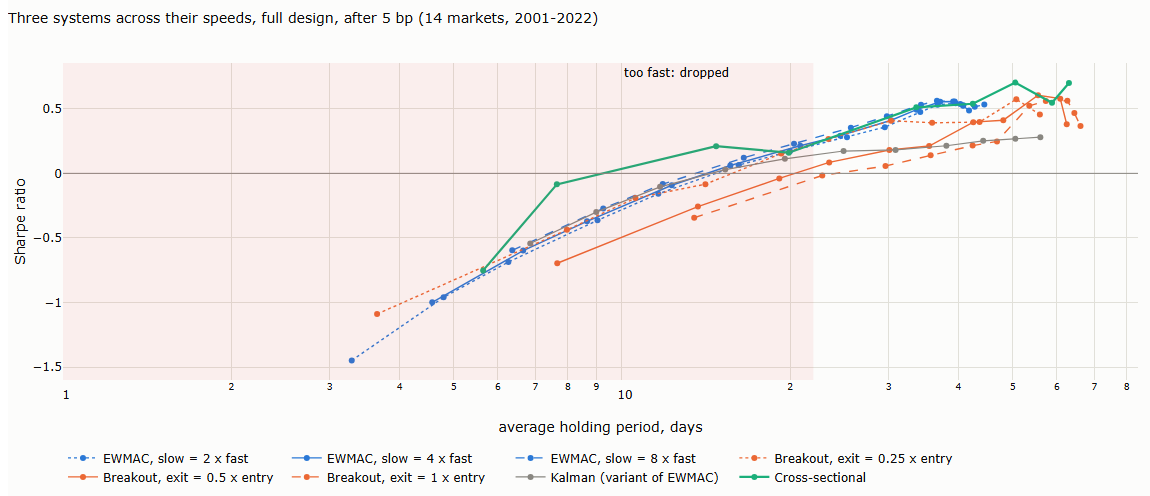

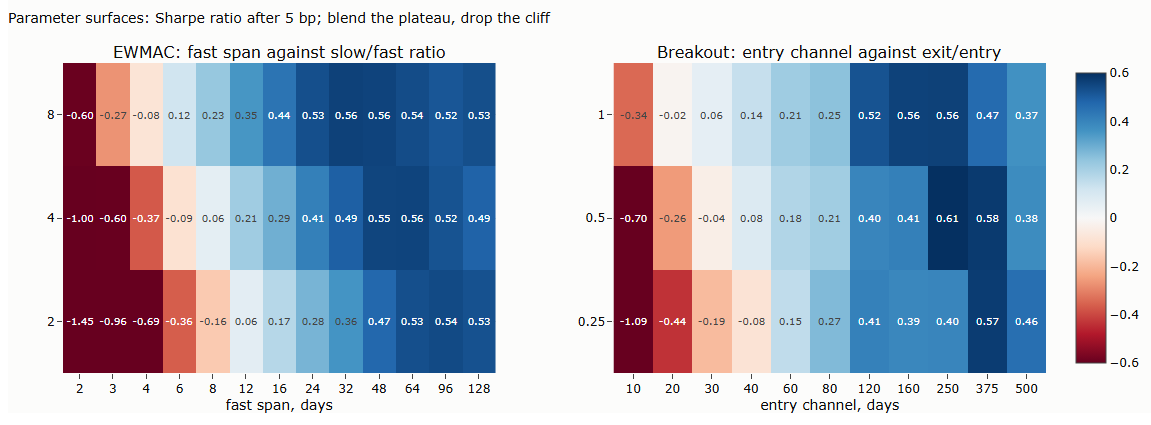

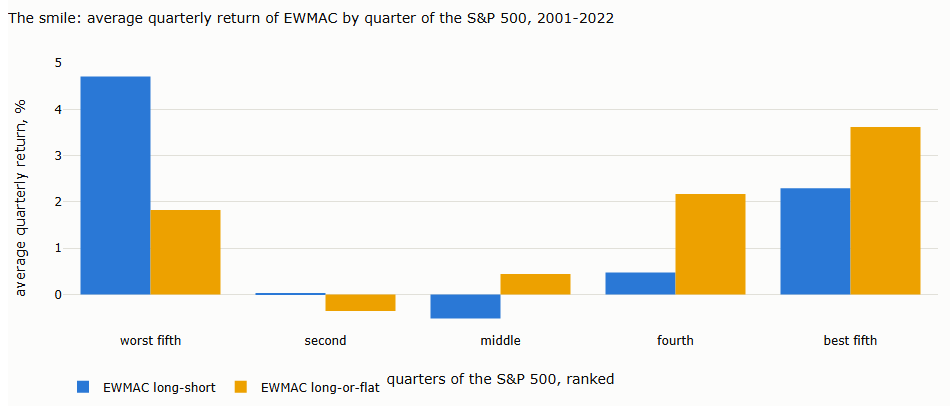

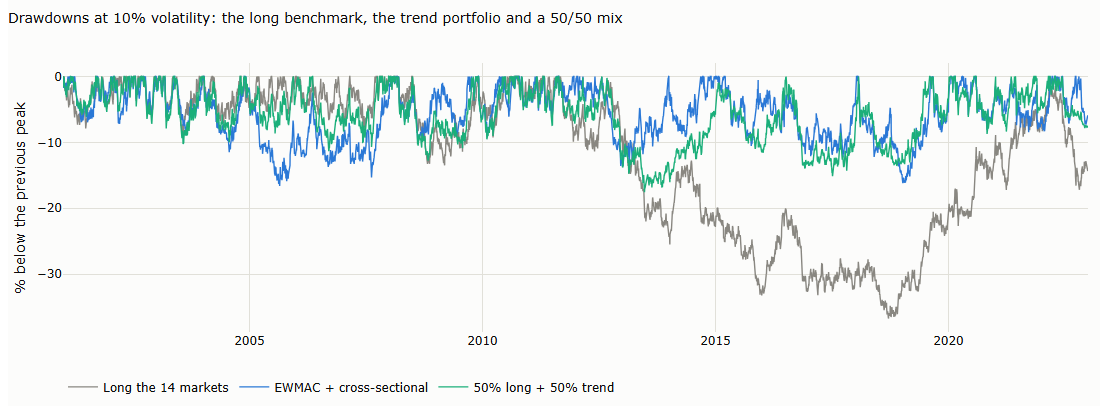

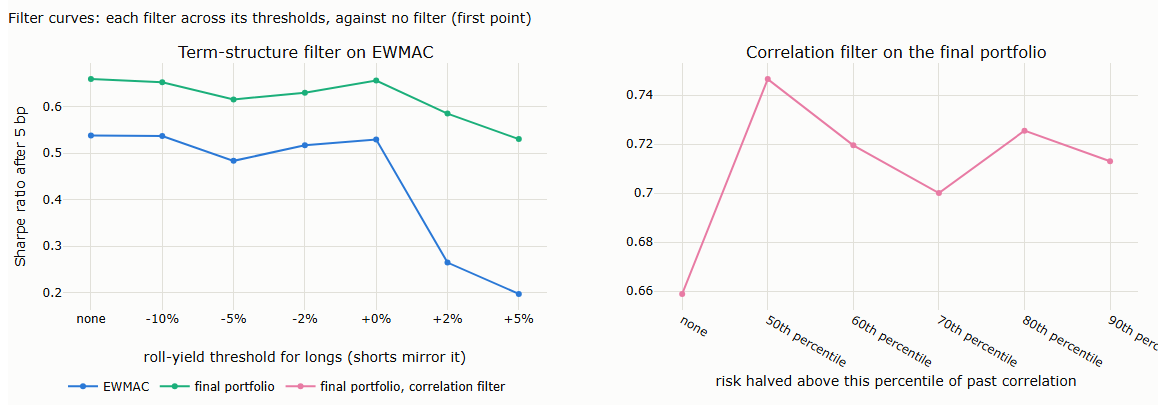

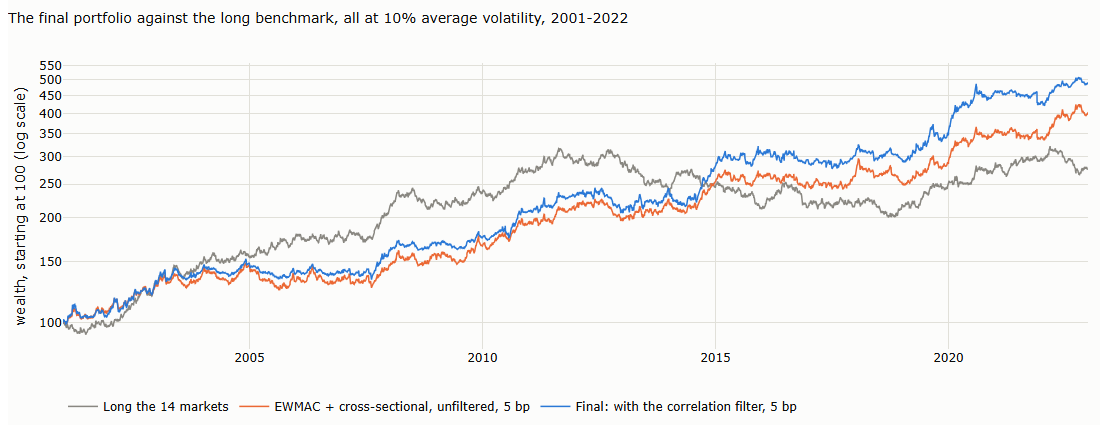

In [24]:
# ---------------- charts J.5-J.10
SC = {"EWMAC": SERIES[0], "Breakout": SERIES[1], "Kalman": MUTED, "Cross-sectional": SERIES[2]}
fig = go.Figure()
for s_, g in SUR.groupby("system", sort=False):
    if s_ in ("EWMAC", "Breakout"):
        for p2, gg in g.groupby("p2"):
            gg = gg.sort_values("hold")
            dash = {2: "dot", 4: "solid", 8: "dash", 0.25: "dot", 0.5: "solid", 1.0: "dash"}[p2]
            nm = f"EWMAC, slow = {int(p2)} x fast" if s_ == "EWMAC" else f"Breakout, exit = {p2:g} x entry"
            fig.add_scatter(x=gg.hold, y=gg.sharpe, mode="lines+markers", name=nm, line=dict(color=SC[s_], width=1.4, dash=dash))
    else:
        g = g.sort_values("hold")
        fig.add_scatter(x=g.hold, y=g.sharpe, mode="lines+markers", name=s_ + (" (variant of EWMAC)" if s_ == "Kalman" else ""), line=dict(color=SC[s_], width=1.2 if s_ == "Kalman" else 2.2))
fig.add_hline(y=0, line=dict(color=MUTED, width=1))
fig.add_vrect(x0=1, x1=22, fillcolor="rgba(220,60,60,0.07)", line_width=0, annotation_text="too fast: dropped", annotation_position="top left")
fig.update_layout(title="Three systems across their speeds, full design, after 5 bp (14 markets, 2001-2022)", xaxis=dict(title="average holding period, days", type="log"),
                  yaxis_title="Sharpe ratio", height=520, width=1150, margin=dict(t=80), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "11_05_speed_curves", FIG)

fig = make_subplots(rows=1, cols=2, subplot_titles=("EWMAC: fast span against slow/fast ratio", "Breakout: entry channel against exit/entry"), horizontal_spacing=0.12)
for j, (s_, xs) in enumerate((("EWMAC", "fast span, days"), ("Breakout", "entry channel, days"))):
    m_ = SUR[SUR.system == s_].pivot(index="p2", columns="p1", values="sharpe")
    fig.add_heatmap(z=m_.values, x=[str(int(v)) for v in m_.columns], y=[f"{v:g}" for v in m_.index], zmin=-0.6, zmax=0.6, colorscale="RdBu",
                    text=np.vectorize(lambda v: f"{v:.2f}")(m_.values), texttemplate="%{text}", textfont=dict(size=10), showscale=(j == 1), row=1, col=j + 1)
    fig.update_xaxes(title_text=xs, type="category", row=1, col=j + 1); fig.update_yaxes(type="category", row=1, col=j + 1)
fig.update_layout(title="Parameter surfaces: Sharpe ratio after 5 bp; blend the plateau, drop the cliff", height=430, width=1150, margin=dict(t=80))
save_figure(fig, "11_06_surfaces", FIG)

fig = go.Figure()
for j, (nm, fc) in enumerate((("EWMAC long-short", F_EW), ("EWMAC long-or-flat", F_EW.clip(lower=0)))):
    x = portfolio(fc); q = (1 + x).resample("QE").prod() - 1; sm = q.groupby(quint.reindex(q.index), observed=True).mean() * 100
    fig.add_bar(x=list(sm.index), y=sm.values, name=nm, marker_color=[SERIES[0], SERIES[4]][j])
fig.update_layout(barmode="group", title="The smile: average quarterly return of EWMAC by quarter of the S&P 500, 2001-2022", xaxis_title="quarters of the S&P 500, ranked",
                  yaxis_title="average quarterly return, %", height=430, width=950, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_07_smile", FIG)

fig = go.Figure()
for nm, x, col in (("Long the 14 markets", LONG, MUTED), ("EWMAC + cross-sectional", FINAL, SERIES[0]), ("50% long + 50% trend", mix, SERIES[2])):
    dd, _ = under_water(x); fig.add_scatter(x=dd.index, y=100 * dd, name=nm, line=dict(color=col, width=1.4))
fig.update_layout(title="Drawdowns at 10% volatility: the long benchmark, the trend portfolio and a 50/50 mix", yaxis_title="% below the previous peak",
                  height=430, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_08_drawdowns", FIG)

fig = make_subplots(rows=1, cols=2, subplot_titles=("Term-structure filter on EWMAC", "Correlation filter on the final portfolio"), horizontal_spacing=0.1)
fig.add_scatter(x=list(TSF.index), y=TSF.ewmac, mode="lines+markers", name="EWMAC", line=dict(color=SERIES[0]), row=1, col=1)
fig.add_scatter(x=list(TSF.index), y=TSF.final, mode="lines+markers", name="final portfolio", line=dict(color=SERIES[2]), row=1, col=1)
fig.add_scatter(x=list(CF.index), y=CF.sharpe, mode="lines+markers", name="final portfolio, correlation filter", line=dict(color=SERIES[3]), row=1, col=2)
fig.update_xaxes(type="category", title_text="roll-yield threshold for longs (shorts mirror it)", row=1, col=1)
fig.update_xaxes(type="category", title_text="risk halved above this percentile of past correlation", row=1, col=2)
fig.update_yaxes(title_text="Sharpe ratio after 5 bp", row=1, col=1)
fig.update_layout(title="Filter curves: each filter across its thresholds, against no filter (first point)", height=430, width=1150, margin=dict(t=80), legend=dict(orientation="h", y=-0.25, x=0))
save_figure(fig, "11_09_filter_curves", FIG)

fig = go.Figure()
for nm, x, col in (("Long the 14 markets", LONG, MUTED), ("EWMAC + cross-sectional, 5 bp", FINAL, SERIES[0]), ("EWMAC + cross-sectional, 10 bp", FINAL10, SERIES[1])):
    fig.add_scatter(x=x.index, y=100 * (1 + x).cumprod(), name=nm, line=dict(color=col, width=1.5))
fig.update_layout(title="The final portfolio against the long benchmark, 10% volatility target, 2001-2022", yaxis=dict(title="wealth, starting at 100 (log scale)", type="log"),
                  height=450, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_10_final", FIG)
print("\ncharts saved")

## §10.1, exploratory: the term structure relative to its own past, and decided at entry

Variants designed after seeing the first result, so exploration rather than confirmation: the roll yield against
its own past year (lowest and highest quartiles), applied every day or decided once when a trend starts (Lecture 8,
attachment C), in the carry direction and in the contrarian direction; with the exposure and turnover each saves.

In [25]:
"""Term-structure filter, relative version: drop a long when the market's roll yield is in the lowest quartile of its own
past year, a short when it is in the highest quartile. Also turnover and gross exposure saved, against the 0% rule."""
import json
import numpy as np, pandas as pd



def roll_yield(ds):
    C = load(ds); held, _ = schedule(C, "oi", start="1999-01-01")
    names = list(C); nxt = {n: names[i + 1] for i, n in enumerate(names[:-1])}
    last = {n: C[n][C[n].Volume > 0].index.max() for n in names}
    out = pd.Series(np.nan, held.index)
    for t, h in held.dropna().items():
        if h in nxt:
            n2 = nxt[h]; a, b = C[h].Close.get(t, np.nan), C[n2].Close.get(t, np.nan)
            if a > 0 and b > 0:
                out[t] = np.log(a / b) / max((last[n2] - last[h]).days / 365.25, 1 / 12)
    return out.reindex(IDX).ffill(limit=5)


RY = pd.DataFrame({k: roll_yield(k) for k in FUT}).reindex(columns=MK)
ryl = RY.shift(1)
lo = RY.rolling(252, min_periods=126).quantile(0.25).shift(1)
hi = RY.rolling(252, min_periods=126).quantile(0.75).shift(1)


def absolute(fc, tau=0.0):
    okl = (ryl > tau) | ryl.isna(); oks = (ryl < -tau) | ryl.isna()
    return fc.where(((fc > 0) & okl) | ((fc < 0) & oks), 0.0)


def relative(fc):
    okl = ~(ryl < lo); oks = ~(ryl > hi)                      # NaN comparisons are False, so missing data never filters
    return fc.where(((fc > 0) & okl) | ((fc < 0) & oks), 0.0)


def efficiency(fc):
    pos = (fc / SIG).loc[START:]
    notional = (pos.abs() * RAW.abs().loc[START:])          # gross exposure per market, in the units of the portfolio
    traded = ((pos - pos.shift(1)).abs() * RAW.abs().loc[START:])
    return float(notional.sum(axis=1).mean()), float(traded.sum(axis=1).mean())


base_n, base_t = efficiency(F_EW)
rows = {}
for nm, fc in (("no filter", F_EW), ("absolute, 0%", absolute(F_EW)), ("relative: lowest / highest quartile of the past year", relative(F_EW))):
    n_, t_ = efficiency(fc)
    rows[nm] = {"Sharpe EWMAC": sharpe(portfolio(fc)), "Sharpe portfolio": sharpe(combo([fc, F_XS])), "max drawdown EWMAC %": 100 * mdd(portfolio(fc)),
                "positions removed": float(((F_EW != 0) & (fc == 0)).loc[START:].mean().mean()),
                "gross exposure vs no filter": n_ / base_n, "turnover vs no filter": t_ / base_t}
T = pd.DataFrame(rows).T
pd.set_option("display.width", 250)
print(T.round(3).to_string())

                                                      Sharpe EWMAC  Sharpe portfolio  max drawdown EWMAC %  positions removed  gross exposure vs no filter  turnover vs no filter
no filter                                                    0.538             0.659               -16.828              0.000                        1.000                  1.000
absolute, 0%                                                 0.529             0.656               -21.214              0.311                        0.754                  0.834
relative: lowest / highest quartile of the past year         0.376             0.589               -25.847              0.263                        0.757                  1.206


In [26]:
import json
import numpy as np, pandas as pd



def at_entry(fc, drop_long, drop_short):
    out = fc.copy()
    for k in fc.columns:
        f = fc[k].values; dl = drop_long[k].values; ds = drop_short[k].values
        res = np.zeros(len(f)); prev, skip = 0.0, False
        for i in range(len(f)):
            s = np.sign(f[i]) if np.isfinite(f[i]) else 0.0
            if s != prev:                                     # a new trend: decide now
                skip = bool(dl[i]) if s > 0 else bool(ds[i]) if s < 0 else False
                prev = s
            res[i] = 0.0 if skip or not np.isfinite(f[i]) else f[i]
        out[k] = res
    return out


cases = {
    "carry, at entry: no long in the lowest quartile, no short in the highest": (ryl < lo, ryl > hi),
    "contrarian, at entry: no long in the highest quartile, no short in the lowest": (ryl > hi, ryl < lo),
    "carry, at entry, sign rule: no long in contango, no short in backwardation": (ryl < 0, ryl > 0),
}
base_n, base_t = efficiency(F_EW)
rows = {"no filter": None}
for nm, (dl, ds) in cases.items():
    rows[nm] = at_entry(F_EW, dl.fillna(False), ds.fillna(False))
T = {}
for nm, fc in rows.items():
    fc = F_EW if fc is None else fc
    n_, t_ = efficiency(fc)
    T[nm] = {"Sharpe EWMAC": sharpe(portfolio(fc)), "Sharpe portfolio": sharpe(combo([fc, F_XS])), "max drawdown EWMAC %": 100 * mdd(portfolio(fc)),
             "positions removed": float(((F_EW != 0) & (fc == 0)).loc[START:].mean().mean()), "gross exposure vs none": n_ / base_n, "turnover vs none": t_ / base_t}
T = pd.DataFrame(T).T
pd.set_option("display.width", 260); pd.set_option("display.max_colwidth", 90)
print(T.round(3).to_string())

                                                                               Sharpe EWMAC  Sharpe portfolio  max drawdown EWMAC %  positions removed  gross exposure vs none  turnover vs none
no filter                                                                             0.538             0.659               -16.828              0.000                   1.000             1.000
carry, at entry: no long in the lowest quartile, no short in the highest              0.561             0.684               -30.769              0.200                   0.846             0.836
contrarian, at entry: no long in the highest quartile, no short in the lowest         0.472             0.662               -17.928              0.336                   0.693             0.687
carry, at entry, sign rule: no long in contango, no short in backwardation            0.447             0.589               -28.221              0.356                   0.735             0.711


## §9.1, §11.3 The final portfolio: with the correlation filter (chart J.10)

Risk halved when the average correlation of the 14 markets over 63 days is above its median to date, known the day
before (§10.2); all measures at 10% average volatility.

                                   sharpe   ret  max_dd  worst_year  y2022  under_water  raw_vol  bear 2001  bear 2007  bear 2020  bear 2022
unfiltered, 5 bp                     0.66  6.59  -16.62      -10.15  17.86         3.22    10.36      27.37      17.64       1.72      23.67
with correlation filter, 5 bp        0.75  7.47  -15.47       -9.26  14.27         3.00     8.03      25.78      17.59       2.21      17.85
with correlation filter, 10 bp       0.64  6.35  -16.39      -10.73  13.56         3.79     8.03      23.43      16.62       1.93      17.20
with correlation filter, no costs    0.86  8.58  -14.72       -7.76  14.99         2.91     8.02      28.17      18.57       2.48      18.52
{
 "breakeven_bp": 38.480136797544105,
 "on_long": [
  6.359199885518401,
  3.1038961006345582,
  0.07385463183693108
 ],
 "mix_sharpe": 0.8013037587888209,
 "mix_mdd": -18.59724025894166,
 "corr_calm": 0.40589891197327405,
 "corr_stress": -0.029955679765484695,
 "dd_corr": 0.21487824261849045


            unfiltered  filtered
2001-12-31         9.8       8.2
2002-12-31        18.2      22.5
2003-12-31         7.2       7.7
2004-12-31         4.8       3.6
2005-12-31       -10.1      -6.6
2006-12-31         3.1       2.0
2007-12-31         6.3      11.7
2008-12-31         8.6       7.2
2009-12-31         6.4       3.8
2010-12-31        17.4      19.8
2011-12-31        10.1      10.5
2012-12-31        -7.1      -9.3
2013-12-31        14.1      15.8
2014-12-31        11.6      14.9
2015-12-31         4.1       9.5
2016-12-31        -6.0      -6.4
2017-12-31         6.3       4.8
2018-12-31        -4.2      -2.1
2019-12-31        13.3      17.4
2020-12-31        25.2      34.0
2021-12-31        -5.2      -7.9
2022-12-31        17.9      14.3


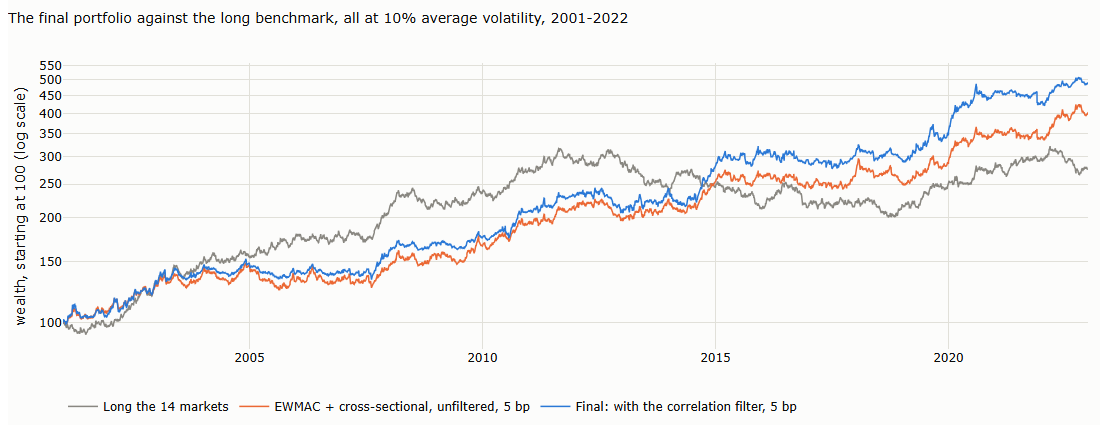

In [27]:
"""The final portfolio with the correlation filter: risk halved when the average correlation of the 14 markets over 63 days
is above its median to date (known the day before). All measures at 10% average volatility, as in §9."""
import json
from pathlib import Path
import numpy as np, pandas as pd

F_EW = blend([ewmac(s, 4) for s in EW_SP])
F_XS = blend([xsec(s) for s in XS_SP])
Z = (D / SIG).loc[:, MK]
RHO = pd.Series(np.nan, IDX)
for i in range(63, len(IDX), 5):
    w = Z.iloc[i - 63:i].dropna(axis=1, how="any")
    if w.shape[1] >= 8:
        cc = np.corrcoef(w.values.T); RHO.iloc[i] = cc[np.triu_indices_from(cc, 1)].mean()
RHO = RHO.ffill()


def filtered(x):
    high = (RHO > RHO.expanding(500).quantile(0.5)).astype(float).shift(1).reindex(x.index).fillna(0).astype(bool)
    return x * np.where(high, 0.5, 1.0)


def at10(x):
    return x / x.std() * TGT


LONG = portfolio(pd.DataFrame(1.0, IDX, MK))
V = {"unfiltered, 5 bp": combo([F_EW, F_XS]), "with correlation filter, 5 bp": filtered(combo([F_EW, F_XS])),
     "with correlation filter, 10 bp": filtered(combo([F_EW, F_XS], cost=0.0010)), "with correlation filter, no costs": filtered(combo([F_EW, F_XS], cost=0.0))}
out = {}
for k, x in V.items():
    y = at10(x)
    w = (1 + y).cumprod(); dd = w / w.cummax() - 1
    best = cur = 0
    for u in (dd < 0).values:
        cur = cur + 1 if u else 0; best = max(best, cur)
    out[k] = dict(sharpe=sharpe(y), ret=100 * 252 * y.mean(), max_dd=100 * dd.min(), worst_year=100 * ((1 + y).resample("YE").prod() - 1).min(),
                  y2022=100 * ((1 + y.loc["2022"]).prod() - 1), under_water=best / 252, raw_vol=100 * np.sqrt(252) * x.std(),
                  **{f"bear {a[:4]}": 100 * ((1 + y.loc[a:b]).prod() - 1) for a, b in BEARS})
T = pd.DataFrame(out).T
pd.set_option("display.width", 250); print(T.round(2).to_string())
F5, F0 = V["with correlation filter, 5 bp"], V["with correlation filter, no costs"]
be = 5 * F0.mean() / (F0 - F5).mean()
a, t, r2 = ols_nw(mon(at10(F5)), mon(LONG).to_frame())
mix = (LONG / LONG.std() + F5 / F5.std()) / 2
dd_long = (lambda w: w / w.cummax() - 1)((1 + at10(LONG)).cumprod())
stress = dd_long < -0.10
y = at10(F5).reindex(LONG.index)
res = dict(table=T.round(3).to_dict("index"), breakeven_bp=float(be), on_long=[1200 * a, t, r2], mix_sharpe=sharpe(mix), mix_mdd=100 * mdd(mix),
           corr_calm=float(y[~stress].corr(LONG[~stress])), corr_stress=float(y[stress].corr(LONG[stress])),
           dd_corr=float(((1 + y).cumprod() / (1 + y).cumprod().cummax() - 1).corr(dd_long)))
print(json.dumps({k: v for k, v in res.items() if k != "table"}, indent=1, default=float))

# chart J.10: the final portfolio with and without the filter, against the long benchmark, all at 10% average volatility
import plotly.graph_objects as go
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure
fig = go.Figure()
for nm, x, col in (("Long the 14 markets", LONG, MUTED), ("EWMAC + cross-sectional, unfiltered, 5 bp", V["unfiltered, 5 bp"], SERIES[1]),
                   ("Final: with the correlation filter, 5 bp", F5, SERIES[0])):
    y_ = at10(x); fig.add_scatter(x=y_.index, y=100 * (1 + y_).cumprod(), name=nm, line=dict(color=col, width=1.5))
fig.update_layout(title="The final portfolio against the long benchmark, all at 10% average volatility, 2001-2022",
                  yaxis=dict(title="wealth, starting at 100 (log scale)", type="log"), height=450, width=1100, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "11_10_final", FIG)
yr = pd.DataFrame({k: (1 + at10(v)).resample("YE").prod() - 1 for k, v in (("unfiltered", V["unfiltered, 5 bp"]), ("filtered", F5))})
print((100 * yr).round(1).to_string())